# 01 — Initial Data Understanding
## PACE stage: Analyze

Purpose: inspect the raw dataset before making cleaning decisions. Do not remove records yet.

In [2]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path('../data/raw/Online Retail.xlsx')
df = pd.read_excel(DATA_PATH)
print('Dataset loaded successfully.')


Dataset loaded successfully.


In [3]:
# Basic structure
print('Shape:', df.shape)
display(df.head())
df.info()


Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
# Missing values and duplicate rows
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame('missing_count'))
print('Duplicate rows:', df.duplicated().sum())


,missing_count
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


Duplicate rows: 5268


In [5]:
# Initial numerical summary
display(df[['Quantity', 'UnitPrice']].describe().T)
print('Date range:', df['InvoiceDate'].min(), 'to', df['InvoiceDate'].max())


,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0


Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [6]:
# Inspect cancellation and unusual values — do not filter yet
invoice_text = df['InvoiceNo'].astype(str)
print('Cancellation invoice rows:', invoice_text.str.startswith('C', na=False).sum())
print('Negative quantity rows:', (df['Quantity'] < 0).sum())
print('Zero/negative unit price rows:', (df['UnitPrice'] <= 0).sum())
print('Missing customer IDs:', df['CustomerID'].isna().sum())


Cancellation invoice rows: 9288
Negative quantity rows: 10624
Zero/negative unit price rows: 2517
Missing customer IDs: 135080


In [7]:
# Investigate unusual transaction records

# 1. Inspect cancellation transactions
cancellations = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancellation examples:")
display(cancellations.head(10))


# 2. Inspect negative quantities
negative_quantity = df[df["Quantity"] < 0]

print("Negative quantity examples:")
display(negative_quantity.head(10))


# 3. Inspect zero or negative unit prices
unusual_prices = df[df["UnitPrice"] <= 0]

print("Unusual price examples:")
display(unusual_prices.head(10))


# 4. Inspect duplicate records
duplicates = df[df.duplicated(keep=False)]

print("Duplicate record examples:")
display(duplicates.head(10))

Cancellation examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


Negative quantity examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


Unusual price examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


Duplicate record examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [8]:
# Detailed data-quality investigation

# Transaction indicators
is_cancellation = df["InvoiceNo"].astype(str).str.startswith("C")
is_negative_quantity = df["Quantity"] < 0
is_zero_price = df["UnitPrice"] == 0
is_negative_price = df["UnitPrice"] < 0

# Count each category
print("Cancellations:", is_cancellation.sum())
print("Negative quantities:", is_negative_quantity.sum())
print("Zero prices:", is_zero_price.sum())
print("Negative prices:", is_negative_price.sum())

# Understand overlap
print("\nOverlap analysis:")
print(
    "Cancellations with negative quantities:",
    (is_cancellation & is_negative_quantity).sum()
)

print(
    "Negative quantities without cancellation prefix:",
    (~is_cancellation & is_negative_quantity).sum()
)

# Duplicate analysis
print("\nDuplicate analysis:")
print("Duplicate rows (excluding first occurrence):", df.duplicated().sum())
print("All rows belonging to duplicate groups:", df.duplicated(keep=False).sum())

# Inspect negative prices separately
print("\nNegative price examples:")
display(df[is_negative_price].head(10))

# Inspect cancellation records with positive quantities
print("\nCancellation records with positive quantities:")
display(df[is_cancellation & (df["Quantity"] > 0)].head(10))

Cancellations: 9288
Negative quantities: 10624
Zero prices: 2515
Negative prices: 2

Overlap analysis:
Cancellations with negative quantities: 9288
Negative quantities without cancellation prefix: 1336

Duplicate analysis:
Duplicate rows (excluding first occurrence): 5268
All rows belonging to duplicate groups: 10147

Negative price examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



Cancellation records with positive quantities:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


In [9]:
# STAGE 2: DATA QUALITY INVESTIGATION

# Identify transaction categories
is_cancellation = df["InvoiceNo"].astype(str).str.startswith("C")
is_negative_quantity = df["Quantity"] < 0
is_zero_price = df["UnitPrice"] == 0
is_negative_price = df["UnitPrice"] < 0

# 1. Count unusual records
print("Cancellations:", is_cancellation.sum())
print("Negative quantities:", is_negative_quantity.sum())
print("Zero prices:", is_zero_price.sum())
print("Negative prices:", is_negative_price.sum())

# 2. Investigate overlap
print("\n--- OVERLAP ANALYSIS ---")

print(
    "Cancellations with negative quantities:",
    (is_cancellation & is_negative_quantity).sum()
)

print(
    "Negative quantities without cancellation prefix:",
    (~is_cancellation & is_negative_quantity).sum()
)

# 3. Investigate duplicate records
print("\n--- DUPLICATE ANALYSIS ---")

print("Exact duplicate occurrences:", df.duplicated().sum())
print("Rows belonging to duplicate groups:", df.duplicated(keep=False).sum())

# 4. Inspect negative prices
print("\n--- NEGATIVE PRICE EXAMPLES ---")
display(df[is_negative_price].head(10))

# 5. Cancellation records with positive quantities
print("\n--- CANCELLATIONS WITH POSITIVE QUANTITIES ---")
display(df[is_cancellation & (df["Quantity"] > 0)].head(10))

Cancellations: 9288
Negative quantities: 10624
Zero prices: 2515
Negative prices: 2

--- OVERLAP ANALYSIS ---
Cancellations with negative quantities: 9288
Negative quantities without cancellation prefix: 1336

--- DUPLICATE ANALYSIS ---
Exact duplicate occurrences: 5268
Rows belonging to duplicate groups: 10147

--- NEGATIVE PRICE EXAMPLES ---


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



--- CANCELLATIONS WITH POSITIVE QUANTITIES ---


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


In [10]:
# Investigate negative quantities without cancellation prefixes

other_negative = df[
    (~is_cancellation) & (df["Quantity"] < 0)
]

print("Total records:", len(other_negative))

print("\nDescription frequency:")
display(other_negative["Description"].value_counts().head(20))

print("\nInvoice number examples:")
display(other_negative.head(20))

print("\nQuantity statistics:")
display(other_negative["Quantity"].describe())

Total records: 1336

Description frequency:


Description
check                         120
damages                        45
damaged                        42
?                              41
sold as set on dotcom          20
Damaged                        14
thrown away                     9
Unsaleable, destroyed.          9
??                              7
damages?                        5
wet damaged                     5
ebay                            5
smashed                         4
missing                         3
CHECK                           3
wet pallet                      3
Dotcom sales                    2
reverse 21/5/10 adjustment      2
counted                         2
crushed                         2
Name: count, dtype: int64


Invoice number examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom



Quantity statistics:


count    1336.000000
mean     -154.907934
std       588.292456
min     -9600.000000
25%       -84.000000
50%       -30.000000
75%        -8.000000
max        -1.000000
Name: Quantity, dtype: float64

In [11]:
# STAGE 2: INVESTIGATE NON-CANCELLATION NEGATIVE QUANTITIES

print("Total records:", len(other_negative))

print("\nPrice analysis:")
print("Zero unit price:",
      (other_negative["UnitPrice"] == 0).sum())

print("Positive unit price:",
      (other_negative["UnitPrice"] > 0).sum())

print("Negative unit price:",
      (other_negative["UnitPrice"] < 0).sum())

print("\nCustomer analysis:")
print("Missing CustomerID:",
      other_negative["CustomerID"].isna().sum())

print("Identified CustomerID:",
      other_negative["CustomerID"].notna().sum())

print("\nRecorded transaction value:")
other_negative = other_negative.copy()

other_negative["LineRevenue"] = (
    other_negative["Quantity"] * other_negative["UnitPrice"]
)

print(other_negative["LineRevenue"].describe())

print("\nRecords with non-zero prices:")
display(
    other_negative[other_negative["UnitPrice"] != 0].head(15)
)

Total records: 1336

Price analysis:
Zero unit price: 1336
Positive unit price: 0
Negative unit price: 0

Customer analysis:
Missing CustomerID: 1336
Identified CustomerID: 0

Recorded transaction value:
count    1336.0
mean        0.0
std         0.0
min        -0.0
25%        -0.0
50%        -0.0
75%         0.0
max        -0.0
Name: LineRevenue, dtype: float64

Records with non-zero prices:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineRevenue


In [12]:
# STAGE 2: ZERO-PRICE TRANSACTION INVESTIGATION

zero_price = df[df["UnitPrice"] == 0].copy()

print("Total zero-price records:", len(zero_price))

print("\nQuantity classification:")
print("Positive quantities:", (zero_price["Quantity"] > 0).sum())
print("Negative quantities:", (zero_price["Quantity"] < 0).sum())
print("Zero quantities:", (zero_price["Quantity"] == 0).sum())

print("\nCustomer identification:")
print("Missing CustomerID:", zero_price["CustomerID"].isna().sum())
print("Identified CustomerID:", zero_price["CustomerID"].notna().sum())

print("\nCancellation classification:")
print(
    "Cancellation records:",
    zero_price["InvoiceNo"].astype(str).str.startswith("C").sum()
)

print("\nMost frequent descriptions:")
display(zero_price["Description"].value_counts().head(20))

print("\nSample positive-quantity zero-price records:")
display(zero_price[zero_price["Quantity"] > 0].head(15))

Total zero-price records: 2515

Quantity classification:
Positive quantities: 1179
Negative quantities: 1336
Zero quantities: 0

Customer identification:
Missing CustomerID: 2475
Identified CustomerID: 40

Cancellation classification:
Cancellation records: 0

Most frequent descriptions:


Description
check                              159
?                                   47
damages                             45
damaged                             43
found                               25
sold as set on dotcom               20
adjustment                          16
Damaged                             14
FRENCH BLUE METAL DOOR SIGN 1        9
thrown away                          9
Unsaleable, destroyed.               9
amazon                               8
FRENCH BLUE METAL DOOR SIGN 8        8
Found                                8
FRENCH BLUE METAL DOOR SIGN 4        7
FRENCH BLUE METAL DOOR SIGN No       7
OWL DOORSTOP                         7
FRENCH BLUE METAL DOOR SIGN 3        7
RECIPE BOX PANTRY YELLOW DESIGN      7
??                                   7
Name: count, dtype: int64


Sample positive-quantity zero-price records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
4348,536765,84952C,NaN,19,2010-12-02 14:43:00,0.0,NaN,United Kingdom


In [13]:
# STAGE 2: INVESTIGATE POSITIVE-QUANTITY ZERO-PRICE RECORDS

zero_price_positive = zero_price[
    zero_price["Quantity"] > 0
].copy()

print("Total records:", len(zero_price_positive))

print("\nCustomer identification:")
display(
    zero_price_positive[
        zero_price_positive["CustomerID"].notna()
    ]
)

print("\nMost frequent descriptions:")
display(
    zero_price_positive["Description"]
    .value_counts(dropna=False)
    .head(25)
)

print("\nInvoice examples:")
display(
    zero_price_positive[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "CustomerID"]
    ].head(25)
)

print("\nQuantity statistics:")
display(zero_price_positive["Quantity"].describe())

Total records: 1179

Customer identification:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom



Most frequent descriptions:


Description
NaN                                592
check                               39
found                               25
adjustment                          14
FRENCH BLUE METAL DOOR SIGN 1        9
amazon                               8
FRENCH BLUE METAL DOOR SIGN 8        8
Found                                8
FRENCH BLUE METAL DOOR SIGN 4        7
FRENCH BLUE METAL DOOR SIGN No       7
OWL DOORSTOP                         7
FRENCH BLUE METAL DOOR SIGN 3        7
RECIPE BOX PANTRY YELLOW DESIGN      7
Amazon                               7
FRENCH BLUE METAL DOOR SIGN 7        6
FRENCH BLUE METAL DOOR SIGN 5        6
FRENCH BLUE METAL DOOR SIGN 6        6
RED KITCHEN SCALES                   6
?                                    6
FRENCH BLUE METAL DOOR SIGN 9        6
MINT KITCHEN SCALES                  6
Manual                               6
BOX OF 24 COCKTAIL PARASOLS          5
IVORY KITCHEN SCALES                 5
CHILDS GARDEN SPADE BLUE             5
Name: count, 


Invoice examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,CustomerID
622,536414,22139,NaN,56,2010-12-01 11:52:00,NaN
1970,536545,21134,NaN,1,2010-12-01 14:32:00,NaN
1971,536546,22145,NaN,1,2010-12-01 14:33:00,NaN
1972,536547,37509,NaN,1,2010-12-01 14:33:00,NaN
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,NaN
1988,536550,85044,NaN,1,2010-12-01 14:34:00,NaN
2024,536552,20950,NaN,1,2010-12-01 14:34:00,NaN
2025,536553,37461,NaN,3,2010-12-01 14:35:00,NaN
2026,536554,84670,NaN,23,2010-12-01 14:35:00,NaN
4348,536765,84952C,NaN,19,2010-12-02 14:43:00,NaN



Quantity statistics:


count     1179.000000
mean        61.580153
std        453.493889
min          1.000000
25%          1.000000
50%          3.000000
75%         20.000000
max      12540.000000
Name: Quantity, dtype: float64

In [14]:
# STAGE 2: INVESTIGATE EXACT DUPLICATE RECORDS

duplicates = df[df.duplicated(keep=False)].copy()

print("Rows belonging to duplicate groups:", len(duplicates))
print("Exact duplicate occurrences:", df.duplicated().sum())

print("\nMost frequent duplicate groups:")

duplicate_groups = (
    duplicates
    .groupby(list(df.columns), dropna=False)
    .size()
    .reset_index(name="Occurrences")
    .sort_values("Occurrences", ascending=False)
)

display(duplicate_groups.head(20))

print("\nSample duplicate records:")

display(
    duplicates.sort_values(
        ["InvoiceNo", "StockCode", "InvoiceDate"]
    ).head(30)
)

Rows belonging to duplicate groups: 10147
Exact duplicate occurrences: 5268

Most frequent duplicate groups:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Occurrences
1613,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,20
1612,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,12
3202,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,2011-10-26 12:46:00,1.25,14102.0,United Kingdom,8
3146,572344,M,Manual,48,2011-10-24 10:43:00,1.50,14607.0,United Kingdom,6
4249,578289,23395,BELLE JARDINIERE CUSHION COVER,1,2011-11-23 14:07:00,3.75,17841.0,United Kingdom,6
474,540524,21756,BATH BUILDING BLOCK WORD,1,2011-01-09 12:53:00,5.95,16735.0,United Kingdom,6
528,541266,21754,HOME BUILDING BLOCK WORD,1,2011-01-16 16:25:00,5.95,15673.0,United Kingdom,6
347,538514,21756,BATH BUILDING BLOCK WORD,1,2010-12-12 14:27:00,5.95,15044.0,United Kingdom,6
529,541266,21755,LOVE BUILDING BLOCK WORD,1,2011-01-16 16:25:00,5.95,15673.0,United Kingdom,6
352,538517,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-12 16:05:00,3.75,17618.0,United Kingdom,5



Sample duplicate records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [15]:
# STAGE 2: MEASURE THE IMPACT OF EXACT DUPLICATES

df_analysis = df.copy()

# Calculate recorded transaction value
df_analysis["LineRevenue"] = (
    df_analysis["Quantity"] * df_analysis["UnitPrice"]
)

# Identify exact duplicate occurrences (keep first occurrence)
duplicate_mask = df_analysis.duplicated(
    subset=list(df.columns),
    keep="first"
)

duplicate_rows = df_analysis[duplicate_mask].copy()
unique_rows = df_analysis[~duplicate_mask].copy()

print("ORIGINAL DATA")
print("Total rows:", len(df_analysis))
print("Total recorded revenue:", round(df_analysis["LineRevenue"].sum(), 2))

print("\nEXACT DUPLICATE OCCURRENCES")
print("Duplicate rows:", len(duplicate_rows))
print("Revenue in duplicate rows:", round(duplicate_rows["LineRevenue"].sum(), 2))

print("\nAFTER REMOVING EXACT DUPLICATES")
print("Remaining rows:", len(unique_rows))
print("Remaining recorded revenue:", round(unique_rows["LineRevenue"].sum(), 2))

print("\nREVENUE DIFFERENCE")
print(
    "Revenue difference:",
    round(
        df_analysis["LineRevenue"].sum()
        - unique_rows["LineRevenue"].sum(),
        2
    )
)

print("\nDUPLICATE GROUP COUNT")
print("Unique exact duplicate groups:", len(duplicate_groups))

ORIGINAL DATA
Total rows: 541909
Total recorded revenue: 9747747.93

EXACT DUPLICATE OCCURRENCES
Duplicate rows: 5268
Revenue in duplicate rows: 21740.98

AFTER REMOVING EXACT DUPLICATES
Remaining rows: 536641
Remaining recorded revenue: 9726006.95

REVENUE DIFFERENCE
Revenue difference: 21740.98

DUPLICATE GROUP COUNT
Unique exact duplicate groups: 4879


In [16]:
# STAGE 2: INVESTIGATE NON-STANDARD STOCK CODES

print("Most frequent stock codes:")

display(
    df["StockCode"]
    .value_counts(dropna=False)
    .head(30)
)

print("\nRecords with non-numeric or unusual stock codes:")

unusual_codes = df[
    ~df["StockCode"].astype(str).str.match(r"^\d+$")
].copy()

display(
    unusual_codes[
        ["StockCode", "Description", "Quantity",
         "UnitPrice", "InvoiceNo"]
    ].head(40)
)

print("\nUnique unusual stock codes:")
display(
    unusual_codes["StockCode"]
    .value_counts()
    .head(30)
)

Most frequent stock codes:


StockCode
85123A    2313
22423     2203
85099B    2159
47566     1727
20725     1639
84879     1502
22720     1477
22197     1476
21212     1385
20727     1350
22383     1348
22457     1280
23203     1267
POST      1256
22386     1251
22469     1239
22960     1229
21931     1214
22086     1210
22411     1202
20728     1197
22382     1192
22961     1182
22666     1180
23298     1179
22699     1138
22384     1137
23209     1135
82482     1129
22993     1111
Name: count, dtype: int64


Records with non-numeric or unusual stock codes:


,StockCode,Description,Quantity,UnitPrice,InvoiceNo
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,536365
2,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,536365
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,536365
4,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,536365
45,POST,POSTAGE,3,18.00,536370
49,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,536373
51,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,536373
60,82494L,WOODEN FRAME ANTIQUE WHITE,6,2.55,536373
61,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,536373
62,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,536373



Unique unusual stock codes:


StockCode
85123A     2313
85099B     2159
POST       1256
85099C      960
82494L      943
85099F      842
DOT         710
M           571
84970S      546
84596B      541
84997D      481
84029G      474
15056N      467
84970L      460
84029E      452
84596F      452
47591D      446
85049E      423
47590B      402
47590A      394
47566B      379
84997B      377
85014B      355
84030E      346
84536A      346
84997C      339
85049A      332
15056BL     326
84032A      318
84406B      296
Name: count, dtype: int64

In [17]:
# STAGE 2: INVESTIGATE SPECIAL TRANSACTION CODES

special_codes = ["POST", "DOT", "M", "D", "PADS", "B"]

special_records = df[
    df["StockCode"].astype(str).isin(special_codes)
].copy()

special_records["LineRevenue"] = (
    special_records["Quantity"] * special_records["UnitPrice"]
)

summary = (
    special_records
    .groupby("StockCode")
    .agg(
        Description=("Description", "first"),
        Records=("InvoiceNo", "count"),
        TotalQuantity=("Quantity", "sum"),
        AveragePrice=("UnitPrice", "mean"),
        RecordedRevenue=("LineRevenue", "sum")
    )
    .reset_index()
)

display(summary)

print("\nInvoice cancellation status:")

special_records["IsCancellation"] = (
    special_records["InvoiceNo"].astype(str).str.startswith("C")
)

display(
    special_records.groupby(
        ["StockCode", "IsCancellation"]
    ).size().unstack(fill_value=0)
)

print("\nSample records:")

display(
    special_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "LineRevenue"]
    ].head(30)
)

,StockCode,Description,Records,TotalQuantity,AveragePrice,RecordedRevenue
0,B,Adjust bad debt,3,3,-3687.353333,-11062.060
1,D,Discount,77,-1194,72.484545,-5696.220
2,DOT,DOTCOM POSTAGE,710,1707,290.495859,206245.480
3,M,Manual,571,3164,375.566392,-68674.190
4,PADS,PADS TO MATCH ALL CUSHIONS,4,4,0.000750,0.003
5,POST,POSTAGE,1256,6353,36.933495,66230.640



Invoice cancellation status:


IsCancellation,False,True
StockCode,,
B,3,0
D,0,77
DOT,709,1
M,327,244
PADS,4,0
POST,1130,126



Sample records:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineRevenue
45,536370,POST,POSTAGE,3,18.00,54.00
141,C536379,D,Discount,-1,27.50,-27.50
386,536403,POST,POSTAGE,1,15.00,15.00
1123,536527,POST,POSTAGE,1,18.00,18.00
1814,536544,DOT,DOTCOM POSTAGE,1,569.77,569.77
2239,536569,M,Manual,1,1.25,1.25
2250,536569,M,Manual,1,18.95,18.95
3041,536592,DOT,DOTCOM POSTAGE,1,607.49,607.49
5073,536840,POST,POSTAGE,1,18.00,18.00
5258,536852,POST,POSTAGE,1,18.00,18.00


In [18]:
# STAGE 2: INVESTIGATE MANUAL AND BAD DEBT ENTRIES

# Manual entries
manual = df[df["StockCode"] == "M"].copy()
manual["LineRevenue"] = manual["Quantity"] * manual["UnitPrice"]

print("MANUAL ENTRIES")
print("Total records:", len(manual))

print("\nRevenue classification:")
display(
    manual.groupby(
        pd.cut(
            manual["LineRevenue"],
            bins=[-float("inf"), -0.001, 0, float("inf")],
            labels=["Negative", "Zero", "Positive"]
        ),
        observed=False
    )
    .agg(
        Records=("LineRevenue", "size"),
        TotalRevenue=("LineRevenue", "sum")
    )
)

print("\nManual entries with the largest negative revenue:")
display(
    manual.nsmallest(20, "LineRevenue")[
        ["InvoiceNo", "Description", "Quantity",
         "UnitPrice", "LineRevenue", "CustomerID"]
    ]
)

print("\nManual entries with the largest positive revenue:")
display(
    manual.nlargest(15, "LineRevenue")[
        ["InvoiceNo", "Description", "Quantity",
         "UnitPrice", "LineRevenue", "CustomerID"]
    ]
)

# Bad debt entries
bad_debt = df[df["StockCode"] == "B"].copy()
bad_debt["LineRevenue"] = bad_debt["Quantity"] * bad_debt["UnitPrice"]

print("\nBAD DEBT ENTRIES")
display(
    bad_debt[
        ["InvoiceNo", "Description", "Quantity",
         "UnitPrice", "LineRevenue", "CustomerID", "InvoiceDate"]
    ]
)

MANUAL ENTRIES
Total records: 571

Revenue classification:


,Records,TotalRevenue
LineRevenue,,
Negative,244,-146784.46
Zero,6,0.00
Positive,321,78110.27



Manual entries with the largest negative revenue:


,InvoiceNo,Description,Quantity,UnitPrice,LineRevenue,CustomerID
222681,C556445,Manual,-1,38970.00,-38970.00,15098.0
422375,C573079,Manual,-2,4161.06,-8322.12,12536.0
173391,C551699,Manual,-1,6930.00,-6930.00,16029.0
268027,C560372,Manual,-1,4287.63,-4287.63,17448.0
406404,C571750,Manual,-1,3949.32,-3949.32,12744.0
293842,C562647,Manual,-1,3155.95,-3155.95,15502.0
271151,C560647,Manual,-1,3060.60,-3060.60,18102.0
347947,C567352,Manual,-1,2653.95,-2653.95,NaN
119631,C546557,Manual,-1,2583.76,-2583.76,NaN
144831,C548830,Manual,-1,2382.92,-2382.92,12744.0



Manual entries with the largest positive revenue:


,InvoiceNo,Description,Quantity,UnitPrice,LineRevenue,CustomerID
268028,560373,Manual,1,4287.63,4287.63,NaN
422351,573077,Manual,1,4161.06,4161.06,12536.0
422376,573080,Manual,1,4161.06,4161.06,12536.0
406406,571751,Manual,1,3949.32,3949.32,12744.0
374542,569382,Manual,1,3155.95,3155.95,15502.0
347948,567353,Manual,1,2653.95,2653.95,NaN
119632,546558,Manual,1,2583.76,2583.76,NaN
297438,562946,Manual,1,2500.00,2500.00,15581.0
144826,548813,Manual,1,2382.92,2382.92,12744.0
406407,571751,Manual,1,2118.74,2118.74,12744.0



BAD DEBT ENTRIES


,InvoiceNo,Description,Quantity,UnitPrice,LineRevenue,CustomerID,InvoiceDate
299982,A563185,Adjust bad debt,1,11062.06,11062.06,NaN,2011-08-12 14:50:00
299983,A563186,Adjust bad debt,1,-11062.06,-11062.06,NaN,2011-08-12 14:51:00
299984,A563187,Adjust bad debt,1,-11062.06,-11062.06,NaN,2011-08-12 14:52:00


In [19]:
# STAGE 2: BUILD A TRANSACTION CATEGORY SUMMARY

special_codes = ["POST", "DOT", "M", "D", "B", "PADS"]

df_classification = df.copy()

df_classification["TransactionCategory"] = "Merchandise"

df_classification.loc[
    df_classification["StockCode"].isin(special_codes),
    "TransactionCategory"
] = "Special / Non-merchandise"

df_classification.loc[
    df_classification["InvoiceNo"].astype(str).str.startswith("C"),
    "TransactionCategory"
] = "Cancellation"

df_classification.loc[
    df_classification["StockCode"].isin(special_codes),
    "TransactionCategory"
] = df_classification.loc[
    df_classification["StockCode"].isin(special_codes),
    "StockCode"
].map({
    "POST": "Postage",
    "DOT": "Dotcom postage",
    "M": "Manual adjustment",
    "D": "Discount",
    "B": "Bad debt adjustment",
    "PADS": "Special product / adjustment"
})

df_classification["LineRevenue"] = (
    df_classification["Quantity"] * df_classification["UnitPrice"]
)

display(
    df_classification.groupby("TransactionCategory")
    .agg(
        Records=("InvoiceNo", "count"),
        RecordedRevenue=("LineRevenue", "sum")
    )
    .sort_values("Records", ascending=False)
)

,Records,RecordedRevenue
TransactionCategory,,
Merchandise,530448,1.029316e+07
Cancellation,8840,-7.324573e+05
Postage,1256,6.623064e+04
Dotcom postage,710,2.062455e+05
Manual adjustment,571,-6.867419e+04
Discount,77,-5.696220e+03
Special product / adjustment,4,3.000000e-03
Bad debt adjustment,3,-1.106206e+04


In [20]:
# STAGE 2: RECONCILE TRANSACTION TYPES AND CANCELLATIONS

df_check = df.copy()

# Identify cancellation invoices independently
df_check["IsCancellation"] = (
    df_check["InvoiceNo"].astype(str).str.startswith("C")
)

# Assign transaction categories based on stock codes
category_map = {
    "POST": "Postage",
    "DOT": "Dotcom postage",
    "M": "Manual adjustment",
    "D": "Discount",
    "B": "Bad debt adjustment",
    "PADS": "Special product / adjustment"
}

df_check["TransactionCategory"] = (
    df_check["StockCode"]
    .map(category_map)
    .fillna("Merchandise")
)

df_check["LineRevenue"] = (
    df_check["Quantity"] * df_check["UnitPrice"]
)

# Cross-tabulation
reconciliation = (
    df_check
    .groupby(["TransactionCategory", "IsCancellation"])
    .agg(
        Records=("InvoiceNo", "count"),
        RecordedRevenue=("LineRevenue", "sum")
    )
    .reset_index()
)

display(reconciliation)

print("\nCANCELLATION RECONCILIATION")

print(
    "Total cancellation records:",
    df_check["IsCancellation"].sum()
)

print(
    "Total cancellation records with negative quantities:",
    (
        df_check["IsCancellation"] &
        (df_check["Quantity"] < 0)
    ).sum()
)

print(
    "Total cancellation records with positive quantities:",
    (
        df_check["IsCancellation"] &
        (df_check["Quantity"] > 0)
    ).sum()
)

print("\nTOTAL RECORDS:", len(df_check))

,TransactionCategory,IsCancellation,Records,RecordedRevenue
0,Bad debt adjustment,False,3,-1.106206e+04
1,Discount,True,77,-5.696220e+03
2,Dotcom postage,False,709,2.062488e+05
3,Dotcom postage,True,1,-3.290000e+00
4,Manual adjustment,False,327,7.811027e+04
5,Manual adjustment,True,244,-1.467845e+05
6,Merchandise,False,530448,1.029316e+07
7,Merchandise,True,8840,-7.324573e+05
8,Postage,False,1130,7.810188e+04
9,Postage,True,126,-1.187124e+04



CANCELLATION RECONCILIATION
Total cancellation records: 9288
Total cancellation records with negative quantities: 9288
Total cancellation records with positive quantities: 0

TOTAL RECORDS: 541909


In [21]:
# STAGE 3: CREATE THE MERCHANDISE ANALYSIS DATASET

special_codes = ["POST", "DOT", "M", "D", "B", "PADS"]

is_special = df["StockCode"].astype(str).isin(special_codes)
is_cancellation = df["InvoiceNo"].astype(str).str.startswith("C")
is_positive_quantity = df["Quantity"] > 0
is_positive_price = df["UnitPrice"] > 0

# Apply the merchandise selection rules
merchandise_mask = (
    ~is_special &
    ~is_cancellation &
    is_positive_quantity &
    is_positive_price
)

df_merchandise = df.loc[merchandise_mask].copy()

# Calculate recorded line revenue
df_merchandise["LineRevenue"] = (
    df_merchandise["Quantity"] * df_merchandise["UnitPrice"]
)

print("MERCHANDISE DATASET SUMMARY")
print("---------------------------")

print("Original records:", len(df))
print("Merchandise records:", len(df_merchandise))
print("Excluded records:", len(df) - len(df_merchandise))

print(
    "Recorded merchandise revenue: £{:,.2f}".format(
        df_merchandise["LineRevenue"].sum()
    )
)

print("Unique invoices:", df_merchandise["InvoiceNo"].nunique())
print("Unique stock codes:", df_merchandise["StockCode"].nunique())

print(
    "Records with missing CustomerID:",
    df_merchandise["CustomerID"].isna().sum()
)

print(
    "Records with missing Description:",
    df_merchandise["Description"].isna().sum()
)

print(
    "Exact duplicate occurrences:",
    df_merchandise.duplicated().sum()
)

print(
    "Date range:",
    df_merchandise["InvoiceDate"].min(),
    "to",
    df_merchandise["InvoiceDate"].max()
)

MERCHANDISE DATASET SUMMARY
---------------------------
Original records: 541909
Merchandise records: 527947
Excluded records: 13962
Recorded merchandise revenue: £10,293,161.56
Unique invoices: 19791
Unique stock codes: 3917
Records with missing CustomerID: 131465
Records with missing Description: 0
Exact duplicate occurrences: 5221
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [22]:
# STAGE 3: VALIDATE THE MERCHANDISE DATASET

print("MERCHANDISE DATASET VALIDATION")
print("------------------------------")

print(
    "Special transaction codes remaining:",
    df_merchandise["StockCode"].astype(str).isin(special_codes).sum()
)

print(
    "Cancellation invoices remaining:",
    df_merchandise["InvoiceNo"].astype(str).str.startswith("C").sum()
)

print(
    "Zero or negative quantities:",
    (df_merchandise["Quantity"] <= 0).sum()
)

print(
    "Zero or negative unit prices:",
    (df_merchandise["UnitPrice"] <= 0).sum()
)

print(
    "Missing descriptions:",
    df_merchandise["Description"].isna().sum()
)

print(
    "Missing CustomerIDs:",
    df_merchandise["CustomerID"].isna().sum()
)

print(
    "Revenue recalculation check:",
    (
        df_merchandise["Quantity"] * df_merchandise["UnitPrice"]
    ).equals(df_merchandise["LineRevenue"])
)

MERCHANDISE DATASET VALIDATION
------------------------------
Special transaction codes remaining: 0
Cancellation invoices remaining: 0
Zero or negative quantities: 0
Zero or negative unit prices: 0
Missing descriptions: 0
Missing CustomerIDs: 131465
Revenue recalculation check: True


In [23]:
# STAGE 3: SAVE THE CLEANED MERCHANDISE DATASET

import os

os.makedirs("../data/processed", exist_ok=True)

output_path = "../data/processed/merchandise_cleaned.csv"

df_merchandise.to_csv(output_path, index=False)

print("Dataset saved successfully.")
print("File:", output_path)
print("Rows saved:", len(df_merchandise))
print(
    "Recorded merchandise revenue: £{:,.2f}".format(
        df_merchandise["LineRevenue"].sum()
    )
)

Dataset saved successfully.
File: ../data/processed/merchandise_cleaned.csv
Rows saved: 527947
Recorded merchandise revenue: £10,293,161.56


In [24]:
# STAGE 4: TOP 20 PRODUCTS BY RECORDED REVENUE

product_performance = (
    df_merchandise
    .groupby(["StockCode", "Description"])
    .agg(
        UnitsSold=("Quantity", "sum"),
        RecordedRevenue=("LineRevenue", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        TransactionRecords=("InvoiceNo", "count")
    )
    .reset_index()
    .sort_values("RecordedRevenue", ascending=False)
)

display(product_performance.head(20).round(2))

,StockCode,Description,UnitsSold,RecordedRevenue,InvoiceCount,TransactionRecords
1262,22423,REGENCY CAKESTAND 3 TIER,13879,174484.74,1988,2017
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1,1
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189,2256
2669,47566,PARTY BUNTING,18295,99504.33,1685,1706
3761,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089,2112
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247,250
1951,23084,RABBIT NIGHT LIGHT,30788,66964.99,994,1036
944,22086,PAPER CHAIN KIT 50'S CHRISTMAS,19355,64952.29,1160,1200
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93,1455,1489
2737,79321,CHILLI LIGHTS,10306,54117.76,661,670


In [25]:
# STAGE 4: INVESTIGATE UNUSUAL PRODUCT PERFORMANCE

products_to_investigate = ["23843", "22502", "23166"]

investigation = df_merchandise[
    df_merchandise["StockCode"].astype(str).isin(products_to_investigate)
].copy()

investigation["StockCode"] = investigation["StockCode"].astype(str)

display(
    investigation[
        [
            "InvoiceNo",
            "InvoiceDate",
            "StockCode",
            "Description",
            "Quantity",
            "UnitPrice",
            "LineRevenue",
            "CustomerID"
        ]
    ].sort_values(
        ["StockCode", "LineRevenue"],
        ascending=[True, False]
    )
)

,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,LineRevenue,CustomerID
222680,556444,2011-06-10 15:28:00,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,15098.0
222682,556446,2011-06-10 15:33:00,22502,PICNIC BASKET WICKER 60 PIECES,1,649.50,649.50,15098.0
180755,552342,2011-05-09 12:07:00,22502,PICNIC BASKET WICKER SMALL,96,4.95,475.20,17949.0
222670,556442,2011-06-10 15:22:00,22502,PICNIC BASKET WICKER SMALL,60,4.95,297.00,15098.0
116817,546306,2011-03-10 16:16:00,22502,PICNIC BASKET WICKER SMALL,30,8.95,268.50,NaN
...,...,...,...,...,...,...,...,...
432728,573889,2011-11-01 13:44:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,1,1.25,1.25,13571.0
468894,576560,2011-11-15 13:21:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,1,1.25,1.25,12877.0
500499,578783,2011-11-25 11:58:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,1,1.25,1.25,12748.0
531499,580956,2011-12-06 14:23:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,1,1.25,1.25,17841.0


In [26]:
# STAGE 4: PRODUCT CONCENTRATION AND STOCK-CODE CONSISTENCY

for code in ["23843", "22502", "23166"]:

    product = df_merchandise[
        df_merchandise["StockCode"].astype(str) == code
    ].copy()

    print(f"\nSTOCK CODE: {code}")
    print("Descriptions:", product["Description"].nunique())
    print("Total records:", len(product))
    print("Total units:", product["Quantity"].sum())
    print("Total recorded revenue: £{:,.2f}".format(
        product["LineRevenue"].sum()
    ))

    print("\nLargest individual transactions:")

    display(
        product[
            [
                "InvoiceNo",
                "InvoiceDate",
                "Description",
                "Quantity",
                "UnitPrice",
                "LineRevenue",
                "CustomerID"
            ]
        ]
        .sort_values("LineRevenue", ascending=False)
        .head(10)
    )


STOCK CODE: 23843
Descriptions: 1
Total records: 1
Total units: 80995
Total recorded revenue: £168,469.60

Largest individual transactions:


,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,LineRevenue,CustomerID
540421,581483,2011-12-09 09:15:00,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446.0



STOCK CODE: 22502
Descriptions: 2
Total records: 469
Total units: 1940
Total recorded revenue: £51,426.62

Largest individual transactions:


,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,LineRevenue,CustomerID
222680,556444,2011-06-10 15:28:00,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.0,15098.0
222682,556446,2011-06-10 15:33:00,PICNIC BASKET WICKER 60 PIECES,1,649.50,649.5,15098.0
180755,552342,2011-05-09 12:07:00,PICNIC BASKET WICKER SMALL,96,4.95,475.2,17949.0
222670,556442,2011-06-10 15:22:00,PICNIC BASKET WICKER SMALL,60,4.95,297.0,15098.0
116817,546306,2011-03-10 16:16:00,PICNIC BASKET WICKER SMALL,30,8.95,268.5,NaN
176907,552038,2011-05-06 08:08:00,PICNIC BASKET WICKER SMALL,48,4.95,237.6,14156.0
116099,546212,2011-03-10 11:33:00,PICNIC BASKET WICKER SMALL,48,4.95,237.6,14156.0
71984,542222,2011-01-26 12:42:00,PICNIC BASKET WICKER SMALL,48,4.95,237.6,14616.0
5109,536844,2010-12-02 18:49:00,PICNIC BASKET WICKER SMALL,32,4.95,158.4,14236.0
152290,549585,2011-04-11 09:54:00,PICNIC BASKET WICKER SMALL,32,4.95,158.4,14616.0



STOCK CODE: 23166
Descriptions: 1
Total records: 250
Total units: 78033
Total recorded revenue: £81,700.92

Largest individual transactions:


,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,LineRevenue,CustomerID
61619,541431,2011-01-18 10:01:00,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346.0
285367,561901,2011-07-31 15:42:00,MEDIUM CERAMIC TOP STORAGE JAR,288,1.25,360.00,14156.0
194462,553607,2011-05-18 10:47:00,MEDIUM CERAMIC TOP STORAGE JAR,240,1.04,249.60,16684.0
276513,561051,2011-07-24 13:11:00,MEDIUM CERAMIC TOP STORAGE JAR,144,1.04,149.76,16684.0
201570,554307,2011-05-23 14:59:00,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84,12989.0
186770,552882,2011-05-12 10:10:00,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84,14646.0
228160,556917,2011-06-15 13:37:00,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84,12415.0
304929,563614,2011-08-18 08:51:00,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84,12415.0
485775,577669,2011-11-21 10:48:00,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84,15567.0
526381,580665,2011-12-05 14:06:00,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84,16684.0


In [27]:
# STAGE 4: INVESTIGATE EXCEPTIONAL INVOICES

invoices_to_check = ["581483", "541431"]
customers_to_check = [16446, 12346]

print("COMPLETE INVOICE DETAILS")

for invoice in invoices_to_check:
    print(f"\nINVOICE: {invoice}")

    display(
        df[df["InvoiceNo"].astype(str) == invoice][
            [
                "InvoiceNo",
                "InvoiceDate",
                "StockCode",
                "Description",
                "Quantity",
                "UnitPrice",
                "CustomerID"
            ]
        ]
    )

print("\nCUSTOMER TRANSACTION HISTORIES")

for customer in customers_to_check:
    customer_data = df[
        df["CustomerID"] == customer
    ].copy()

    print(f"\nCUSTOMER ID: {customer}")
    print("Transaction records:", len(customer_data))
    print("Unique invoices:", customer_data["InvoiceNo"].nunique())
    print("Date range:",
          customer_data["InvoiceDate"].min(),
          "to",
          customer_data["InvoiceDate"].max())

    display(
        customer_data.groupby("InvoiceNo")
        .agg(
            InvoiceDate=("InvoiceDate", "min"),
            Records=("InvoiceNo", "count"),
            Quantity=("Quantity", "sum"),
            RecordedRevenue=(
                "UnitPrice",
                lambda prices: (
                    prices * customer_data.loc[prices.index, "Quantity"]
                ).sum()
            )
        )
        .sort_values("InvoiceDate")
        .tail(10)
    )

COMPLETE INVOICE DETAILS

INVOICE: 581483


,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,CustomerID
540421,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0



INVOICE: 541431


,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,CustomerID
61619,541431,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0



CUSTOMER TRANSACTION HISTORIES

CUSTOMER ID: 16446
Transaction records: 4
Unique invoices: 3
Date range: 2011-05-18 09:52:00 to 2011-12-09 09:27:00


,InvoiceDate,Records,Quantity,RecordedRevenue
InvoiceNo,,,,
553573,2011-05-18 09:52:00,2,2,2.9
581483,2011-12-09 09:15:00,1,80995,168469.6
C581484,2011-12-09 09:27:00,1,-80995,-168469.6



CUSTOMER ID: 12346
Transaction records: 2
Unique invoices: 2
Date range: 2011-01-18 10:01:00 to 2011-01-18 10:17:00


,InvoiceDate,Records,Quantity,RecordedRevenue
InvoiceNo,,,,
541431,2011-01-18 10:01:00,1,74215,77183.6
C541433,2011-01-18 10:17:00,1,-74215,-77183.6


In [28]:
# STAGE 4: IDENTIFY POTENTIALLY MATCHED CANCELLATIONS

positive = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["CustomerID"].notna())
].copy()

negative_cancellations = df[
    df["InvoiceNo"].astype(str).str.startswith("C") &
    (df["Quantity"] < 0) &
    (df["CustomerID"].notna())
].copy()

# Create matching keys
positive["AbsQuantity"] = positive["Quantity"]
negative_cancellations["AbsQuantity"] = (
    negative_cancellations["Quantity"].abs()
)

match_keys = [
    "CustomerID",
    "StockCode",
    "AbsQuantity",
    "UnitPrice"
]

# Identify matching transaction-line patterns
positive_keys = positive[match_keys].drop_duplicates()
cancellation_keys = negative_cancellations[match_keys].drop_duplicates()

matched_keys = positive_keys.merge(
    cancellation_keys,
    on=match_keys,
    how="inner"
)

print("Positive transaction records:", len(positive))
print("Cancellation transaction records:", len(negative_cancellations))
print("Distinct matching transaction patterns:", len(matched_keys))

# Inspect the two known examples
display(
    matched_keys[
        matched_keys["StockCode"].astype(str).isin(["23843", "23166"])
    ]
)

Positive transaction records: 397884
Cancellation transaction records: 8905
Distinct matching transaction patterns: 2992


,CustomerID,StockCode,AbsQuantity,UnitPrice
414,12346.0,23166,74215,1.04
1361,16684.0,23166,240,1.04
1616,14911.0,23166,12,1.25
1833,12415.0,23166,1,1.25
2501,12607.0,23166,12,1.25
2991,16446.0,23843,80995,2.08


In [29]:
# STAGE 4: MATCH CANCELLATIONS TO EARLIER PURCHASES

match_keys = [
    "CustomerID",
    "StockCode",
    "AbsQuantity",
    "UnitPrice"
]

positive_match = positive.copy()
cancellation_match = negative_cancellations.copy()

positive_match["AbsQuantity"] = positive_match["Quantity"]
cancellation_match["AbsQuantity"] = (
    cancellation_match["Quantity"].abs()
)

positive_match = positive_match.sort_values("InvoiceDate")
cancellation_match = cancellation_match.sort_values("InvoiceDate")

matched_transactions = pd.merge_asof(
    cancellation_match,
    positive_match,
    on="InvoiceDate",
    by=match_keys,
    direction="backward",
    tolerance=pd.Timedelta("1 day"),
    suffixes=("_Cancellation", "_Original")
)

matched_count = matched_transactions["InvoiceNo_Original"].notna().sum()

print("Cancellation records examined:", len(cancellation_match))
print("Matched to an earlier positive record within 24 hours:", matched_count)
print(
    "Unmatched cancellation records:",
    len(cancellation_match) - matched_count
)

print("\nKNOWN EXAMPLES")

display(
    matched_transactions[
        matched_transactions["StockCode"].astype(str).isin(
            ["23843", "23166"]
        )
    ][
        [
            "InvoiceNo_Cancellation",
            "InvoiceNo_Original",
            "StockCode",
            "CustomerID",
            "AbsQuantity",
            "UnitPrice",
            "InvoiceDate"
        ]
    ]
)

Cancellation records examined: 8905
Matched to an earlier positive record within 24 hours: 679
Unmatched cancellation records: 8226

KNOWN EXAMPLES


,InvoiceNo_Cancellation,InvoiceNo_Original,StockCode,CustomerID,AbsQuantity,UnitPrice,InvoiceDate
994,C541433,541431,23166,12346.0,74215,1.04,2011-01-18 10:17:00
3482,C554527,NaN,23166,15251.0,9,1.04,2011-05-24 17:25:00
4012,C557508,NaN,23166,16684.0,240,1.04,2011-06-20 16:13:00
4635,C560540,560491,23166,12415.0,1,1.25,2011-07-19 12:26:00
5019,C562375,562374,23166,14911.0,12,1.25,2011-08-04 14:46:00
5152,C562952,NaN,23166,12749.0,1,1.25,2011-08-11 10:10:00
5969,C567535,NaN,23166,15253.0,1,1.25,2011-09-21 09:50:00
6001,C567677,NaN,23166,12409.0,2,1.04,2011-09-21 15:57:00
7002,C570867,NaN,23166,12607.0,12,1.25,2011-10-12 16:17:00
7410,C572991,NaN,23166,17672.0,1,1.25,2011-10-27 10:56:00


In [30]:
# STAGE 4: CHECK FOR REUSED ORIGINAL TRANSACTIONS

positive_match = positive.copy()
cancellation_match = negative_cancellations.copy()

positive_match["AbsQuantity"] = positive_match["Quantity"]
cancellation_match["AbsQuantity"] = (
    cancellation_match["Quantity"].abs()
)

# Preserve original row identifiers
positive_match["OriginalRowID"] = positive_match.index
cancellation_match["CancellationRowID"] = cancellation_match.index

positive_match = positive_match.sort_values("InvoiceDate")
cancellation_match = cancellation_match.sort_values("InvoiceDate")

matched_check = pd.merge_asof(
    cancellation_match,
    positive_match,
    on="InvoiceDate",
    by=match_keys,
    direction="backward",
    tolerance=pd.Timedelta("1 day"),
    suffixes=("_Cancellation", "_Original")
)

successful_matches = matched_check[
    matched_check["OriginalRowID"].notna()
]

reused_originals = (
    successful_matches["OriginalRowID"]
    .value_counts()
)

print("Preliminary matched cancellations:", len(successful_matches))

print(
    "Original transaction rows matched more than once:",
    (reused_originals > 1).sum()
)

print(
    "Maximum cancellations matched to one original row:",
    reused_originals.max() if len(reused_originals) else 0
)

print(
    "Unique original transaction rows matched:",
    successful_matches["OriginalRowID"].nunique()
)

Preliminary matched cancellations: 679
Original transaction rows matched more than once: 12
Maximum cancellations matched to one original row: 3
Unique original transaction rows matched: 664


In [31]:
# STAGE 4: INSPECT REUSED ORIGINAL TRANSACTIONS

reused_ids = reused_originals[reused_originals > 1].index

collision_details = successful_matches[
    successful_matches["OriginalRowID"].isin(reused_ids)
][
    [
        "CancellationRowID",
        "InvoiceNo_Cancellation",
        "InvoiceDate",
        "OriginalRowID",
        "InvoiceNo_Original",
        "StockCode",
        "CustomerID",
        "AbsQuantity",
        "UnitPrice"
    ]
].sort_values(["OriginalRowID", "InvoiceDate"])

display(collision_details)

,CancellationRowID,InvoiceNo_Cancellation,InvoiceDate,OriginalRowID,InvoiceNo_Original,StockCode,CustomerID,AbsQuantity,UnitPrice
113,12948,C537402,2010-12-06 14:43:00,9779.0,537217,22849,15502.0,4,14.95
120,13012,C537406,2010-12-06 14:53:00,9779.0,537217,22849,15502.0,4,14.95
114,12949,C537402,2010-12-06 14:43:00,9780.0,537217,22847,15502.0,4,14.95
119,13011,C537406,2010-12-06 14:53:00,9780.0,537217,22847,15502.0,4,14.95
112,12947,C537402,2010-12-06 14:43:00,9781.0,537217,22927,15502.0,4,5.95
118,13010,C537406,2010-12-06 14:53:00,9781.0,537217,22927,15502.0,4,5.95
111,12946,C537402,2010-12-06 14:43:00,9782.0,537217,22926,15502.0,4,5.95
117,13009,C537406,2010-12-06 14:53:00,9782.0,537217,22926,15502.0,4,5.95
300,24181,C538341,2010-12-10 14:03:00,24105.0,538313,22726,15514.0,1,3.75
317,24178,C538341,2010-12-10 14:03:00,24105.0,538313,22726,15514.0,1,3.75


In [32]:
# STAGE 4: COMPARE PRODUCT RANKINGS WITHOUT TWO VERIFIED CANCELLED INVOICES

verified_cancelled_invoices = ["581483", "541431"]

df_sensitivity = df_merchandise[
    ~df_merchandise["InvoiceNo"].astype(str).isin(
        verified_cancelled_invoices
    )
].copy()

# Recalculate product performance
product_performance_adjusted = (
    df_sensitivity
    .groupby(["StockCode", "Description"])
    .agg(
        UnitsSold=("Quantity", "sum"),
        RecordedRevenue=("LineRevenue", "sum"),
        InvoiceCount=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("RecordedRevenue", ascending=False)
)

print("ORIGINAL MERCHANDISE REVENUE: £{:,.2f}".format(
    df_merchandise["LineRevenue"].sum()
))

print("ADJUSTED MERCHANDISE REVENUE: £{:,.2f}".format(
    df_sensitivity["LineRevenue"].sum()
))

print(
    "Revenue difference: £{:,.2f}".format(
        df_merchandise["LineRevenue"].sum()
        - df_sensitivity["LineRevenue"].sum()
    )
)

print("\nTOP 20 PRODUCTS AFTER SENSITIVITY ADJUSTMENT")

display(product_performance_adjusted.head(20).round(2))

ORIGINAL MERCHANDISE REVENUE: £10,293,161.56
ADJUSTED MERCHANDISE REVENUE: £10,047,508.36
Revenue difference: £245,653.20

TOP 20 PRODUCTS AFTER SENSITIVITY ADJUSTMENT


,StockCode,Description,UnitsSold,RecordedRevenue,InvoiceCount
1262,22423,REGENCY CAKESTAND 3 TIER,13879,174484.74,1988
3772,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189
2668,47566,PARTY BUNTING,18295,99504.33,1685
3760,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089
1951,23084,RABBIT NIGHT LIGHT,30788,66964.99,994
944,22086,PAPER CHAIN KIT 50'S CHRISTMAS,19355,64952.29,1160
2874,84879,ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93,1455
2736,79321,CHILLI LIGHTS,10306,54117.76,661
2207,23298,SPOTTY BUNTING,8327,42548.13,1140
1229,22386,JUMBO BAG PINK POLKADOT,21465,42436.24,1218


In [33]:
# STAGE 4: PRODUCT REVENUE CONTRIBUTION AND PARETO ANALYSIS

product_contribution = (
    df_sensitivity
    .groupby("StockCode")
    .agg(
        Description=("Description", lambda x: x.mode().iloc[0]),
        DescriptionVariants=("Description", "nunique"),
        UnitsSold=("Quantity", "sum"),
        RecordedRevenue=("LineRevenue", "sum"),
        InvoiceCount=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("RecordedRevenue", ascending=False)
)

total_revenue = product_contribution["RecordedRevenue"].sum()

product_contribution["RevenueSharePct"] = (
    product_contribution["RecordedRevenue"] / total_revenue * 100
)

product_contribution["CumulativeRevenuePct"] = (
    product_contribution["RevenueSharePct"].cumsum()
)

display(
    product_contribution.head(20).round(2)
)

print("\nPRODUCT CONTRIBUTION SUMMARY")
print("Total unique stock codes:", len(product_contribution))
print(
    "Top 10 revenue share: {:.2f}%".format(
        product_contribution.head(10)["RevenueSharePct"].sum()
    )
)
print(
    "Top 20 revenue share: {:.2f}%".format(
        product_contribution.head(20)["RevenueSharePct"].sum()
    )
)
print(
    "Stock codes with multiple descriptions:",
    (product_contribution["DescriptionVariants"] > 1).sum()
)

,StockCode,Description,DescriptionVariants,UnitsSold,RecordedRevenue,InvoiceCount,RevenueSharePct,CumulativeRevenuePct
1235,22423,REGENCY CAKESTAND 3 TIER,1,13879,174484.74,1988,1.74,1.74
3538,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2,37660,104518.80,2198,1.04,2.78
2467,47566,PARTY BUNTING,1,18295,99504.33,1685,0.99,3.77
3527,85099B,JUMBO BAG RED RETROSPOT,1,48474,94340.05,2089,0.94,4.71
1867,23084,RABBIT NIGHT LIGHT,1,30788,66964.99,994,0.67,5.37
931,22086,PAPER CHAIN KIT 50'S CHRISTMAS,1,19355,64952.29,1160,0.65,6.02
2665,84879,ASSORTED COLOUR BIRD ORNAMENT,1,36461,59094.93,1455,0.59,6.61
2531,79321,CHILLI LIGHTS,1,10306,54117.76,661,0.54,7.15
1309,22502,PICNIC BASKET WICKER SMALL,2,1940,51426.62,463,0.51,7.66
1034,22197,POPCORN HOLDER,2,56921,51354.02,1392,0.51,8.17



PRODUCT CONTRIBUTION SUMMARY
Total unique stock codes: 3916
Top 10 revenue share: 8.17%
Top 20 revenue share: 12.02%
Stock codes with multiple descriptions: 220


In [34]:
# STAGE 4: PRODUCT REVENUE CONCENTRATION

thresholds = [50, 80, 90, 95]

print("PRODUCT CONCENTRATION")
print("Total stock codes:", len(product_contribution))
print()

for threshold in thresholds:
    products_needed = (
        product_contribution["CumulativeRevenuePct"].ge(threshold).idxmax()
        + 1
    )

    percentage_of_products = (
        products_needed / len(product_contribution) * 100
    )

    print(
        f"Products needed for {threshold}% of revenue: "
        f"{products_needed} "
        f"({percentage_of_products:.2f}% of stock codes)"
    )

print("\nREVENUE SHARE BY PRODUCT GROUP")

for n in [10, 20, 50, 100, 200, 500]:
    share = product_contribution.head(n)["RevenueSharePct"].sum()
    print(f"Top {n:>3} products: {share:.2f}%")

PRODUCT CONCENTRATION
Total stock codes: 3916

Products needed for 50% of revenue: 337 (8.61% of stock codes)
Products needed for 80% of revenue: 2108 (53.83% of stock codes)
Products needed for 90% of revenue: 1249 (31.89% of stock codes)
Products needed for 95% of revenue: 556 (14.20% of stock codes)

REVENUE SHARE BY PRODUCT GROUP
Top  10 products: 8.17%
Top  20 products: 12.02%
Top  50 products: 20.54%
Top 100 products: 31.37%
Top 200 products: 45.22%
Top 500 products: 67.19%


In [35]:
# CORRECTED PRODUCT CONCENTRATION THRESHOLDS

for threshold in [50, 80, 90, 95]:
    products_needed = (
        product_contribution["CumulativeRevenuePct"]
        .ge(threshold)
        .to_numpy()
        .argmax() + 1
    )

    percentage_of_products = (
        products_needed / len(product_contribution) * 100
    )

    print(
        f"{threshold}% revenue: "
        f"{products_needed} products "
        f"({percentage_of_products:.2f}% of stock codes)"
    )

50% revenue: 248 products (6.33% of stock codes)
80% revenue: 843 products (21.53% of stock codes)
90% revenue: 1352 products (34.53% of stock codes)
95% revenue: 1821 products (46.50% of stock codes)


In [36]:
# STAGE 5: MONTHLY MERCHANDISE REVENUE ANALYSIS

df_sensitivity["Month"] = (
    df_sensitivity["InvoiceDate"].dt.to_period("M")
)

monthly_performance = (
    df_sensitivity
    .groupby("Month")
    .agg(
        RecordedRevenue=("LineRevenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        TransactionRecords=("InvoiceNo", "count")
    )
    .reset_index()
)

monthly_performance["RevenueChangePct"] = (
    monthly_performance["RecordedRevenue"]
    .pct_change() * 100
)

display(monthly_performance.round(2))

print("\nMONTHLY PERFORMANCE SUMMARY")

print(
    "Highest revenue month:",
    monthly_performance.loc[
        monthly_performance["RecordedRevenue"].idxmax(),
        "Month"
    ]
)

print(
    "Lowest revenue month:",
    monthly_performance.loc[
        monthly_performance["RecordedRevenue"].idxmin(),
        "Month"
    ]
)

print(
    "Average monthly recorded revenue: £{:,.2f}".format(
        monthly_performance["RecordedRevenue"].mean()
    )
)

C:\Users\Yash\AppData\Local\Temp\ipykernel_1520\2288583127.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_performance.round(2))


,Month,RecordedRevenue,UnitsSold,InvoiceCount,TransactionRecords,RevenueChangePct
0,2010-12,792167.24,358764,1553,41330,NaN
1,2011-01,595023.81,313217,1081,34155,-24.89
2,2011-02,509167.87,283256,1093,26972,-14.43
3,2011-03,692235.70,377126,1441,35624,35.95
4,2011-04,516754.79,308527,1237,28970,-25.35
5,2011-05,741726.74,395405,1669,35993,43.54
6,2011-06,739426.88,388843,1525,35790,-0.31
7,2011-07,689947.74,401368,1452,38455,-6.69
8,2011-08,726005.16,421459,1340,34339,5.23
9,2011-09,1031430.36,569969,1821,49078,42.07



MONTHLY PERFORMANCE SUMMARY
Highest revenue month: 2011-11
Lowest revenue month: 2011-12
Average monthly recorded revenue: £772,885.26


In [38]:
# STAGE 5: CHECK MONTHLY DATA COVERAGE

monthly_coverage = (
    df_sensitivity
    .groupby(df_sensitivity["InvoiceDate"].dt.to_period("M"))
    .agg(
        FirstTransaction=("InvoiceDate", "min"),
        LastTransaction=("InvoiceDate", "max"),
        ObservedTransactionDays=(
            "InvoiceDate",
            lambda x: x.dt.date.nunique()
        ),
        RecordedRevenue=("LineRevenue", "sum")
    )
    .reset_index(names="Month")
)

monthly_coverage["CalendarDaysInMonth"] = (
    monthly_coverage["Month"].dt.days_in_month
)

monthly_coverage["ObservedDateSpan"] = (
    monthly_coverage["LastTransaction"].dt.normalize()
    - monthly_coverage["FirstTransaction"].dt.normalize()
).dt.days + 1

monthly_coverage["Month"] = (
    monthly_coverage["Month"].astype(str)
)

display(monthly_coverage)

,Month,FirstTransaction,LastTransaction,ObservedTransactionDays,RecordedRevenue,CalendarDaysInMonth,ObservedDateSpan
0,2010-12,2010-12-01 08:26:00,2010-12-23 17:41:00,20,792167.240,31,23
1,2011-01,2011-01-04 10:00:00,2011-01-31 16:59:00,24,595023.810,31,28
2,2011-02,2011-02-01 08:23:00,2011-02-28 17:01:00,24,509167.870,28,28
3,2011-03,2011-03-01 08:30:00,2011-03-31 19:55:00,27,692235.700,31,31
4,2011-04,2011-04-01 08:22:00,2011-04-28 19:53:00,21,516754.790,30,28
5,2011-05,2011-05-01 10:51:00,2011-05-31 15:53:00,25,741726.740,31,31
6,2011-06,2011-06-01 07:37:00,2011-06-30 20:08:00,26,739426.880,30,30
7,2011-07,2011-07-01 08:16:00,2011-07-31 16:04:00,26,689947.740,31,31
8,2011-08,2011-08-01 08:30:00,2011-08-31 17:30:00,26,726005.160,31,31
9,2011-09,2011-09-01 08:25:00,2011-09-30 17:22:00,26,1031430.361,30,30


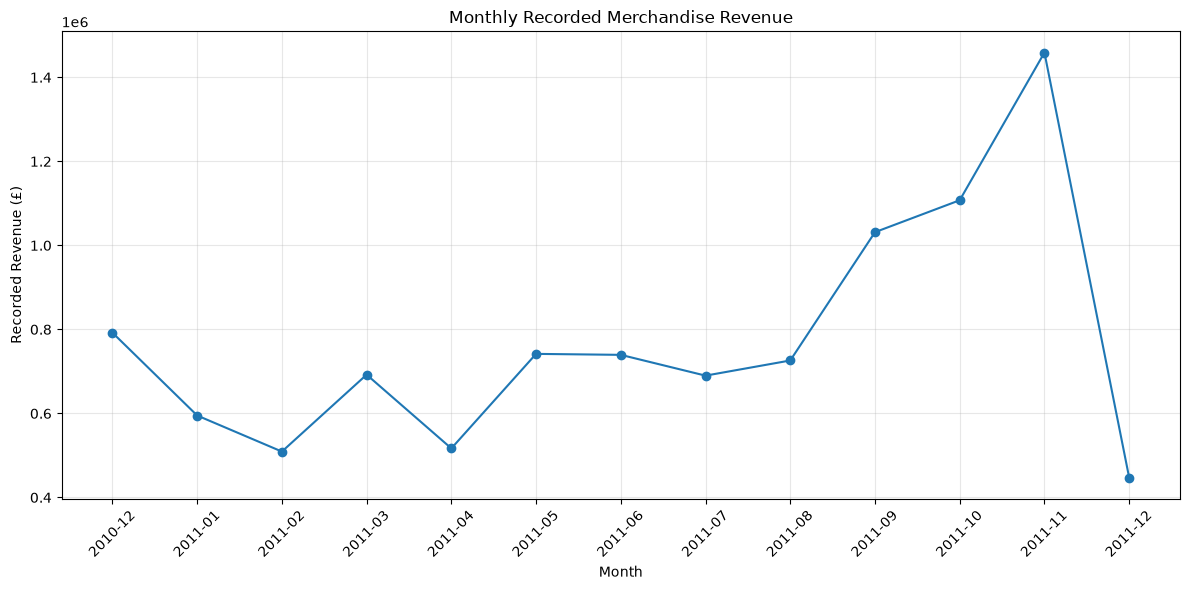

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_performance["Month"].astype(str),
    monthly_performance["RecordedRevenue"],
    marker="o"
)

plt.title("Monthly Recorded Merchandise Revenue")
plt.xlabel("Month")
plt.ylabel("Recorded Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [40]:
# STAGE 5: ANALYSE MONTHLY SALES ACTIVITY

monthly_performance["RevenuePerInvoice"] = (
    monthly_performance["RecordedRevenue"]
    / monthly_performance["InvoiceCount"]
)

monthly_performance["UnitsPerInvoice"] = (
    monthly_performance["UnitsSold"]
    / monthly_performance["InvoiceCount"]
)

display(
    monthly_performance[
        [
            "Month",
            "RecordedRevenue",
            "InvoiceCount",
            "UnitsSold",
            "RevenuePerInvoice",
            "UnitsPerInvoice"
        ]
    ].round(2)
)

C:\Users\Yash\AppData\Local\Temp\ipykernel_1520\3430230890.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Month,RecordedRevenue,InvoiceCount,UnitsSold,RevenuePerInvoice,UnitsPerInvoice
0,2010-12,792167.24,1553,358764,510.09,231.01
1,2011-01,595023.81,1081,313217,550.44,289.75
2,2011-02,509167.87,1093,283256,465.84,259.15
3,2011-03,692235.70,1441,377126,480.39,261.71
4,2011-04,516754.79,1237,308527,417.75,249.42
5,2011-05,741726.74,1669,395405,444.41,236.91
6,2011-06,739426.88,1525,388843,484.87,254.98
7,2011-07,689947.74,1452,401368,475.17,276.42
8,2011-08,726005.16,1340,421459,541.79,314.52
9,2011-09,1031430.36,1821,569969,566.41,313.00


In [41]:
# CLEAN MONTHLY SALES ACTIVITY TABLE

monthly_activity = monthly_performance[
    [
        "Month",
        "RecordedRevenue",
        "InvoiceCount",
        "UnitsSold",
        "RevenuePerInvoice",
        "UnitsPerInvoice"
    ]
].copy()

numeric_columns = monthly_activity.select_dtypes(
    include="number"
).columns

monthly_activity[numeric_columns] = (
    monthly_activity[numeric_columns].round(2)
)

monthly_activity["Month"] = (
    monthly_activity["Month"].astype(str)
)

display(monthly_activity)

,Month,RecordedRevenue,InvoiceCount,UnitsSold,RevenuePerInvoice,UnitsPerInvoice
0,2010-12,792167.24,1553,358764,510.09,231.01
1,2011-01,595023.81,1081,313217,550.44,289.75
2,2011-02,509167.87,1093,283256,465.84,259.15
3,2011-03,692235.70,1441,377126,480.39,261.71
4,2011-04,516754.79,1237,308527,417.75,249.42
5,2011-05,741726.74,1669,395405,444.41,236.91
6,2011-06,739426.88,1525,388843,484.87,254.98
7,2011-07,689947.74,1452,401368,475.17,276.42
8,2011-08,726005.16,1340,421459,541.79,314.52
9,2011-09,1031430.36,1821,569969,566.41,313.00


In [42]:
# STAGE 5: MONTHLY CUSTOMER ACTIVITY

df_sensitivity["Month"] = (
    df_sensitivity["InvoiceDate"].dt.to_period("M")
)

monthly_customers = (
    df_sensitivity
    .groupby("Month")
    .agg(
        IdentifiableCustomers=("CustomerID", "nunique"),
        RecordsWithCustomerID=("CustomerID", "count"),
        TotalRecords=("InvoiceNo", "count"),
        InvoiceCount=("InvoiceNo", "nunique")
    )
    .reset_index()
)

monthly_customers["CustomerIDCoveragePct"] = (
    monthly_customers["RecordsWithCustomerID"]
    / monthly_customers["TotalRecords"] * 100
)

display(monthly_customers.round(2))

C:\Users\Yash\AppData\Local\Temp\ipykernel_1520\1663710881.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_customers.round(2))


,Month,IdentifiableCustomers,RecordsWithCustomerID,TotalRecords,InvoiceCount,CustomerIDCoveragePct
0,2010-12,885,26066,41330,1553,63.07
1,2011-01,738,21141,34155,1081,61.90
2,2011-02,757,19855,26972,1093,73.61
3,2011-03,973,27069,35624,1441,75.99
4,2011-04,853,22563,28970,1237,77.88
5,2011-05,1055,28217,35993,1669,78.40
6,2011-06,990,27090,35790,1525,75.69
7,2011-07,946,26729,38455,1452,69.51
8,2011-08,933,26907,34339,1340,78.36
9,2011-09,1261,39890,49078,1821,81.28


In [43]:
# CLEAN MONTHLY CUSTOMER ACTIVITY TABLE

monthly_customers_clean = monthly_customers.copy()

numeric_columns = monthly_customers_clean.select_dtypes(
    include="number"
).columns

monthly_customers_clean[numeric_columns] = (
    monthly_customers_clean[numeric_columns].round(2)
)

monthly_customers_clean["Month"] = (
    monthly_customers_clean["Month"].astype(str)
)

display(monthly_customers_clean)

,Month,IdentifiableCustomers,RecordsWithCustomerID,TotalRecords,InvoiceCount,CustomerIDCoveragePct
0,2010-12,885,26066,41330,1553,63.07
1,2011-01,738,21141,34155,1081,61.90
2,2011-02,757,19855,26972,1093,73.61
3,2011-03,973,27069,35624,1441,75.99
4,2011-04,853,22563,28970,1237,77.88
5,2011-05,1055,28217,35993,1669,78.40
6,2011-06,990,27090,35790,1525,75.69
7,2011-07,946,26729,38455,1452,69.51
8,2011-08,933,26907,34339,1340,78.36
9,2011-09,1261,39890,49078,1821,81.28


In [44]:
# STAGE 5: REPEAT CUSTOMER ANALYSIS

customer_months = (
    df_sensitivity
    .dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Month"]
    .nunique()
)

repeat_customer_summary = pd.DataFrame({
    "CustomerCategory": [
        "One-month customers",
        "Repeat-month customers"
    ],
    "CustomerCount": [
        (customer_months == 1).sum(),
        (customer_months > 1).sum()
    ]
})

repeat_customer_summary["CustomerSharePct"] = (
    repeat_customer_summary["CustomerCount"]
    / len(customer_months) * 100
)

print("Total identifiable customers:", len(customer_months))

display(repeat_customer_summary.round(2))

Total identifiable customers: 4334


,CustomerCategory,CustomerCount,CustomerSharePct
0,One-month customers,1638,37.79
1,Repeat-month customers,2696,62.21


In [45]:
# STAGE 5: CUSTOMER PURCHASE FREQUENCY

customer_frequency = (
    customer_months
    .value_counts()
    .sort_index()
    .rename_axis("ActiveMonths")
    .reset_index(name="CustomerCount")
)

customer_frequency["CustomerSharePct"] = (
    customer_frequency["CustomerCount"]
    / len(customer_months) * 100
)

customer_frequency["CumulativeCustomerPct"] = (
    customer_frequency["CustomerSharePct"].cumsum()
)

display(customer_frequency.round(2))

print("\nCUSTOMER FREQUENCY SUMMARY")
print("Average active months per customer:",
      round(customer_months.mean(), 2))
print("Maximum active months:",
      customer_months.max())

,ActiveMonths,CustomerCount,CustomerSharePct,CumulativeCustomerPct
0,1,1638,37.79,37.79
1,2,911,21.02,58.81
2,3,532,12.28,71.09
3,4,378,8.72,79.81
4,5,267,6.16,85.97
5,6,168,3.88,89.85
6,7,96,2.22,92.06
7,8,88,2.03,94.09
8,9,72,1.66,95.75
9,10,60,1.38,97.14



CUSTOMER FREQUENCY SUMMARY
Average active months per customer: 3.01
Maximum active months: 13


In [46]:
# STAGE 6: CUSTOMER REVENUE ANALYSIS

customer_performance = (
    df_sensitivity
    .dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        RecordedRevenue=("LineRevenue", "sum"),
        UnitsPurchased=("Quantity", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        TransactionRecords=("InvoiceNo", "count"),
        ActiveMonths=("Month", "nunique")
    )
    .reset_index()
    .sort_values("RecordedRevenue", ascending=False)
)

customer_total_revenue = customer_performance["RecordedRevenue"].sum()

customer_performance["RevenueSharePct"] = (
    customer_performance["RecordedRevenue"]
    / customer_total_revenue * 100
)

customer_performance["CumulativeRevenuePct"] = (
    customer_performance["RevenueSharePct"].cumsum()
)

display(customer_performance.head(20).round(2))

print("\nCUSTOMER REVENUE SUMMARY")
print("Identifiable customers:", len(customer_performance))
print("Top 10 customer revenue share: {:.2f}%".format(
    customer_performance.head(10)["RevenueSharePct"].sum()
))
print("Top 20 customer revenue share: {:.2f}%".format(
    customer_performance.head(20)["RevenueSharePct"].sum()
))

,CustomerID,RecordedRevenue,UnitsPurchased,InvoiceCount,TransactionRecords,ActiveMonths,RevenueSharePct,CumulativeRevenuePct
1688,14646.0,279138.02,196844,72,2060,13,3.28,3.28
4197,18102.0,259657.30,64124,60,431,12,3.05,6.32
3725,17450.0,194550.79,69993,46,337,12,2.28,8.61
1878,14911.0,140450.72,80263,199,5673,13,1.65,10.25
54,12415.0,124564.53,77373,20,713,10,1.46,11.71
1332,14156.0,117379.63,57885,55,1400,12,1.38,13.09
3768,17511.0,91062.38,64549,31,963,13,1.07,14.16
2700,16029.0,72882.09,40207,62,241,12,0.86,15.02
3174,16684.0,66653.56,50255,28,277,9,0.78,15.80
995,13694.0,65039.62,63312,50,568,13,0.76,16.56



CUSTOMER REVENUE SUMMARY
Identifiable customers: 4334
Top 10 customer revenue share: 16.56%
Top 20 customer revenue share: 22.78%


In [47]:
# STAGE 6: CUSTOMER REVENUE CONCENTRATION

customer_thresholds = [50, 80, 90, 95]

print("CUSTOMER REVENUE CONCENTRATION")
print("Total identifiable customers:", len(customer_performance))
print()

for threshold in customer_thresholds:

    customers_needed = (
        customer_performance["CumulativeRevenuePct"]
        .ge(threshold)
        .to_numpy()
        .argmax() + 1
    )

    customer_percentage = (
        customers_needed / len(customer_performance) * 100
    )

    print(
        f"{threshold}% revenue: "
        f"{customers_needed} customers "
        f"({customer_percentage:.2f}% of identifiable customers)"
    )

CUSTOMER REVENUE CONCENTRATION
Total identifiable customers: 4334

50% revenue: 232 customers (5.35% of identifiable customers)
80% revenue: 1166 customers (26.90% of identifiable customers)
90% revenue: 1941 customers (44.79% of identifiable customers)
95% revenue: 2628 customers (60.64% of identifiable customers)


In [48]:
# STAGE 7: COUNTRY-LEVEL REVENUE ANALYSIS

country_performance = (
    df_sensitivity
    .groupby("Country")
    .agg(
        RecordedRevenue=("LineRevenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        IdentifiableCustomers=("CustomerID", "nunique")
    )
    .reset_index()
    .sort_values("RecordedRevenue", ascending=False)
)

total_country_revenue = country_performance["RecordedRevenue"].sum()

country_performance["RevenueSharePct"] = (
    country_performance["RecordedRevenue"]
    / total_country_revenue * 100
)

country_performance["CumulativeRevenuePct"] = (
    country_performance["RevenueSharePct"].cumsum()
)

display(country_performance.head(20).round(2))

print("\nCOUNTRY SUMMARY")
print("Number of countries:", len(country_performance))
print(
    "Top 5 countries revenue share: {:.2f}%".format(
        country_performance.head(5)["RevenueSharePct"].sum()
    )
)

,Country,RecordedRevenue,UnitsSold,InvoiceCount,IdentifiableCustomers,RevenueSharePct,CumulativeRevenuePct
36,United Kingdom,8518060.96,4499225,17914,3916,84.78,84.78
24,Netherlands,283889.34,200258,93,9,2.83,87.60
10,EIRE,276404.30,147168,284,3,2.75,90.35
14,Germany,205569.89,118139,443,94,2.05,92.40
13,France,184768.74,111272,383,87,1.84,94.24
0,Australia,138171.31,83900,56,9,1.38,95.61
31,Spain,55725.11,27731,88,30,0.55,96.17
33,Switzerland,53087.90,30527,50,21,0.53,96.70
20,Japan,37416.37,26016,19,8,0.37,97.07
3,Belgium,36927.34,22962,98,25,0.37,97.44



COUNTRY SUMMARY
Number of countries: 38
Top 5 countries revenue share: 94.24%


In [49]:
# STAGE 7: COUNTRY REVENUE SUMMARY

country_summary = country_performance[
    [
        "Country",
        "RecordedRevenue",
        "RevenueSharePct",
        "InvoiceCount",
        "IdentifiableCustomers"
    ]
].copy()

uk_revenue_share = country_summary.loc[
    country_summary["Country"] == "United Kingdom",
    "RevenueSharePct"
].iloc[0]

international_revenue_share = 100 - uk_revenue_share

print("UK revenue share: {:.2f}%".format(uk_revenue_share))
print(
    "International revenue share: {:.2f}%".format(
        international_revenue_share
    )
)

display(country_summary.head(10).round(2))

UK revenue share: 84.78%
International revenue share: 15.22%


,Country,RecordedRevenue,RevenueSharePct,InvoiceCount,IdentifiableCustomers
36,United Kingdom,8518060.96,84.78,17914,3916
24,Netherlands,283889.34,2.83,93,9
10,EIRE,276404.30,2.75,284,3
14,Germany,205569.89,2.05,443,94
13,France,184768.74,1.84,383,87
0,Australia,138171.31,1.38,56,9
31,Spain,55725.11,0.55,88,30
33,Switzerland,53087.90,0.53,50,21
20,Japan,37416.37,0.37,19,8
3,Belgium,36927.34,0.37,98,25


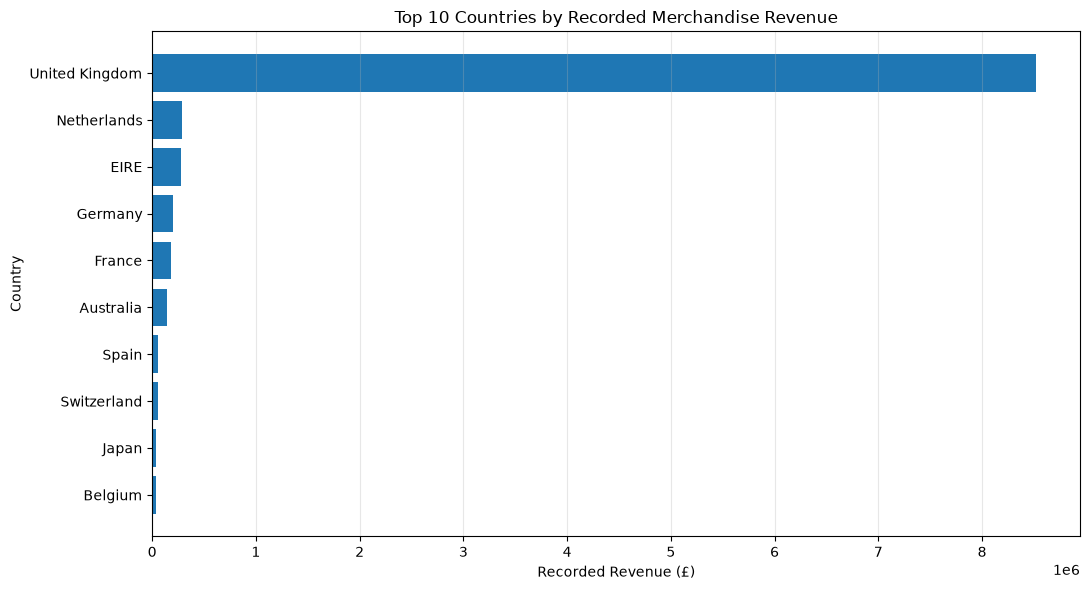

In [50]:
# STAGE 8: COUNTRY REVENUE VISUALIZATION

import matplotlib.pyplot as plt

top_countries = country_performance.head(10).sort_values(
    "RecordedRevenue",
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_countries["Country"],
    top_countries["RecordedRevenue"]
)

plt.title("Top 10 Countries by Recorded Merchandise Revenue")
plt.xlabel("Recorded Revenue (£)")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

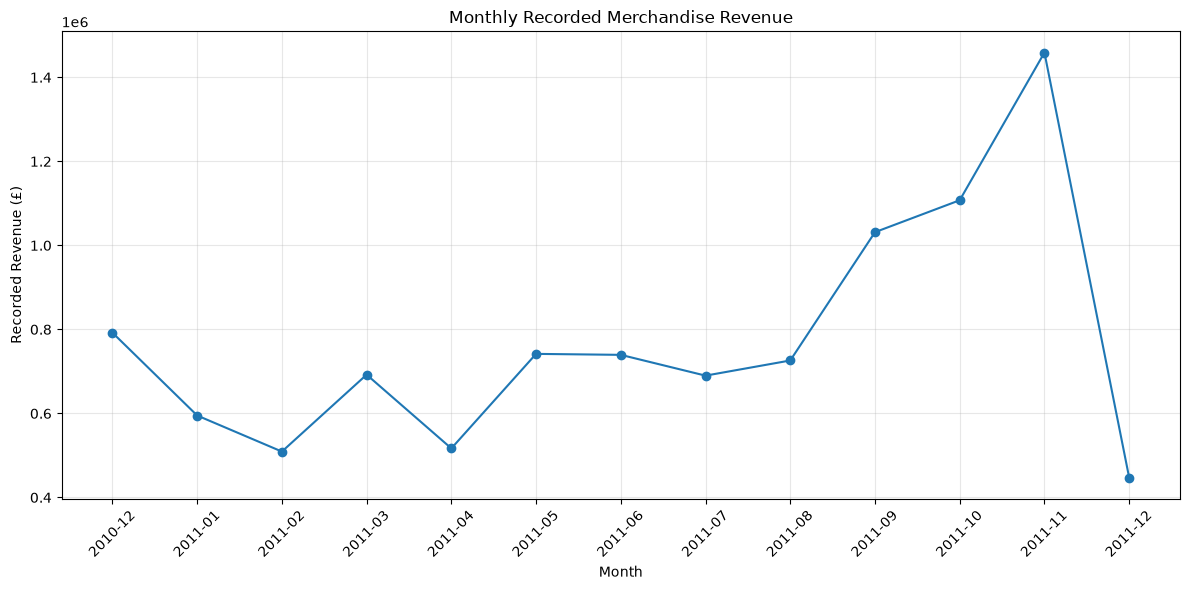

In [51]:
# STAGE 8: MONTHLY REVENUE VISUALIZATION

import matplotlib.pyplot as plt

monthly_chart = monthly_performance.copy()
monthly_chart["Month"] = monthly_chart["Month"].astype(str)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_chart["Month"],
    monthly_chart["RecordedRevenue"],
    marker="o"
)

plt.title("Monthly Recorded Merchandise Revenue")
plt.xlabel("Month")
plt.ylabel("Recorded Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

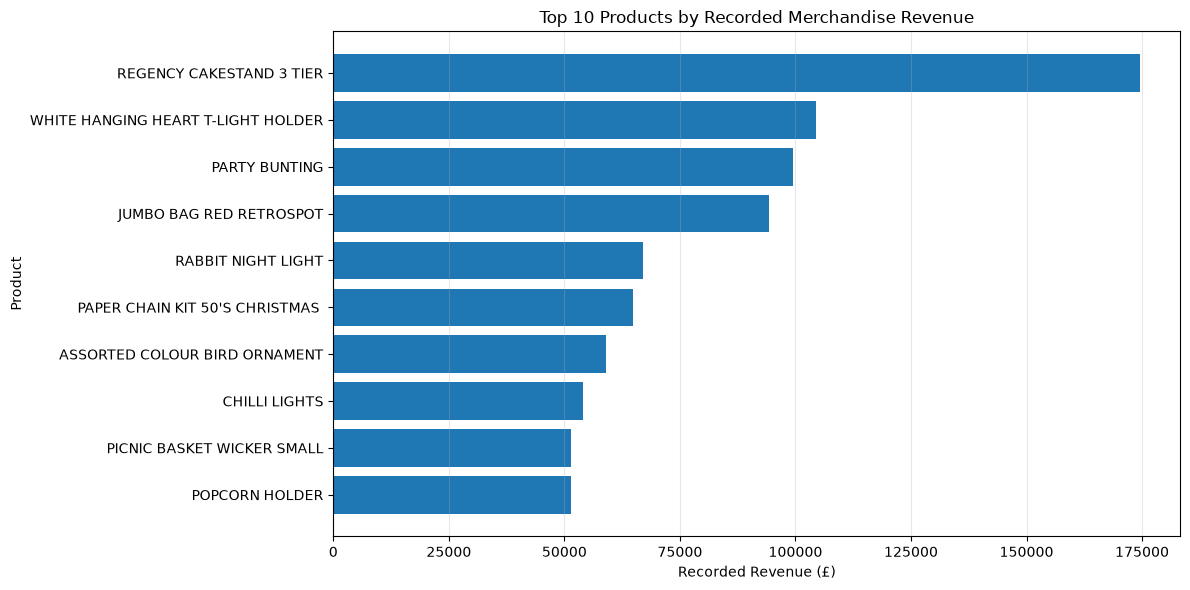

In [52]:
# STAGE 8: TOP 10 PRODUCT REVENUE VISUALIZATION

top_products = (
    product_contribution
    .head(10)
    .sort_values("RecordedRevenue", ascending=True)
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_products["Description"],
    top_products["RecordedRevenue"]
)

plt.title("Top 10 Products by Recorded Merchandise Revenue")
plt.xlabel("Recorded Revenue (£)")
plt.ylabel("Product")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

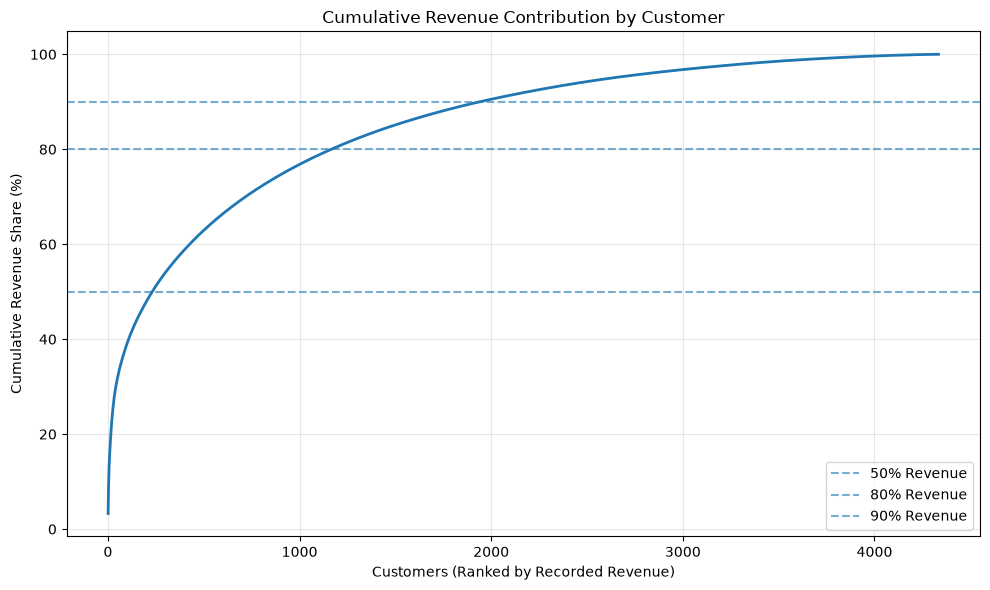

In [53]:
# STAGE 8: CUSTOMER REVENUE CONCENTRATION VISUALIZATION

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(customer_performance) + 1),
    customer_performance["CumulativeRevenuePct"],
    linewidth=2
)

plt.axhline(50, linestyle="--", alpha=0.6, label="50% Revenue")
plt.axhline(80, linestyle="--", alpha=0.6, label="80% Revenue")
plt.axhline(90, linestyle="--", alpha=0.6, label="90% Revenue")

plt.title("Cumulative Revenue Contribution by Customer")
plt.xlabel("Customers (Ranked by Recorded Revenue)")
plt.ylabel("Cumulative Revenue Share (%)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

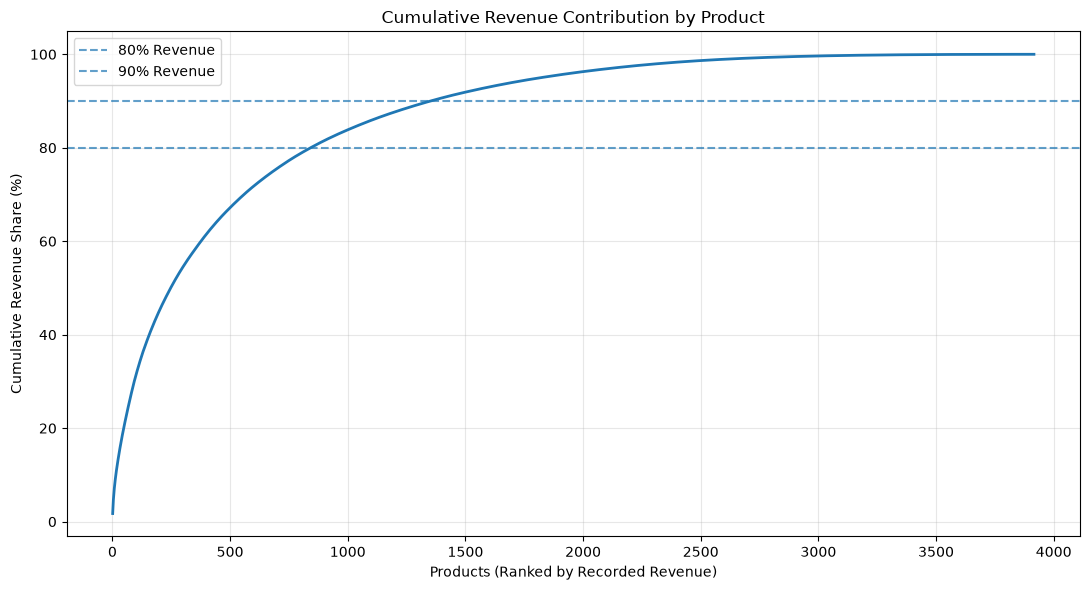

In [54]:
# STAGE 8: PRODUCT REVENUE CONCENTRATION VISUALIZATION

plt.figure(figsize=(11, 6))

plt.plot(
    range(1, len(product_contribution) + 1),
    product_contribution["CumulativeRevenuePct"],
    linewidth=2
)

plt.axhline(
    80,
    linestyle="--",
    alpha=0.7,
    label="80% Revenue"
)

plt.axhline(
    90,
    linestyle="--",
    alpha=0.7,
    label="90% Revenue"
)

plt.title("Cumulative Revenue Contribution by Product")
plt.xlabel("Products (Ranked by Recorded Revenue)")
plt.ylabel("Cumulative Revenue Share (%)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

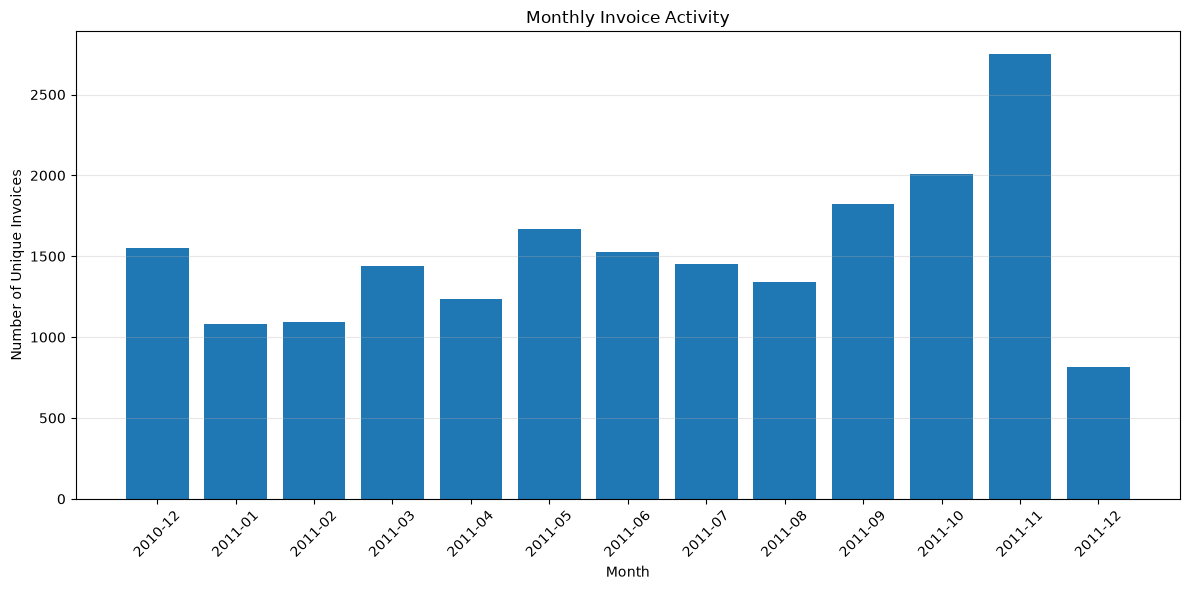

In [55]:
# STAGE 8: MONTHLY INVOICE ACTIVITY VISUALIZATION

monthly_chart = monthly_performance.copy()
monthly_chart["Month"] = monthly_chart["Month"].astype(str)

plt.figure(figsize=(12, 6))

plt.bar(
    monthly_chart["Month"],
    monthly_chart["InvoiceCount"]
)

plt.title("Monthly Invoice Activity")
plt.xlabel("Month")
plt.ylabel("Number of Unique Invoices")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

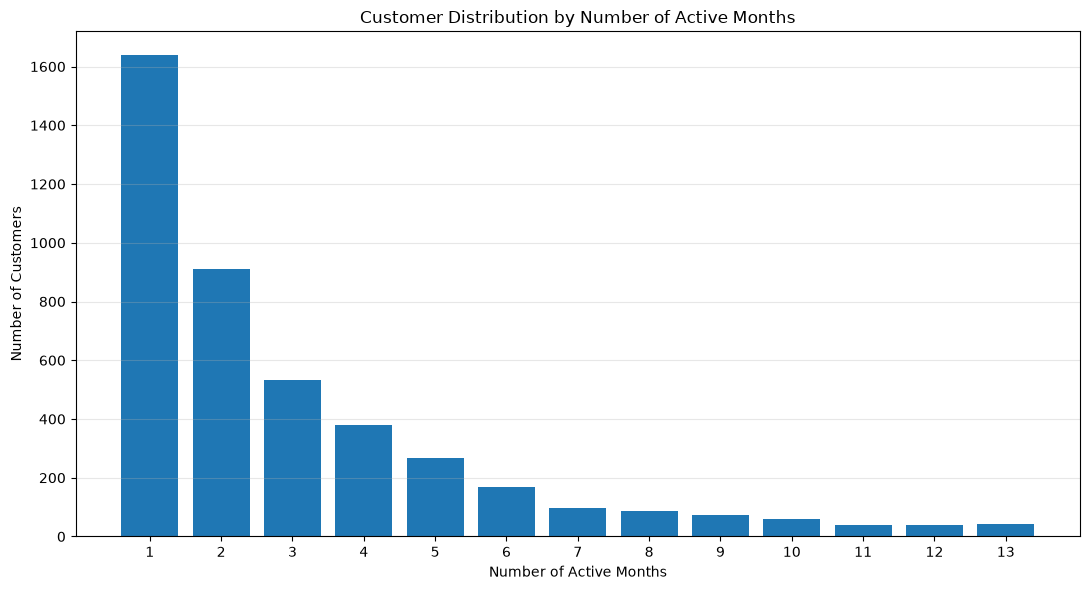

In [56]:
# STAGE 8: CUSTOMER PURCHASE FREQUENCY VISUALIZATION

plt.figure(figsize=(11, 6))

plt.bar(
    customer_frequency["ActiveMonths"],
    customer_frequency["CustomerCount"]
)

plt.title("Customer Distribution by Number of Active Months")
plt.xlabel("Number of Active Months")
plt.ylabel("Number of Customers")
plt.xticks(range(1, 14))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

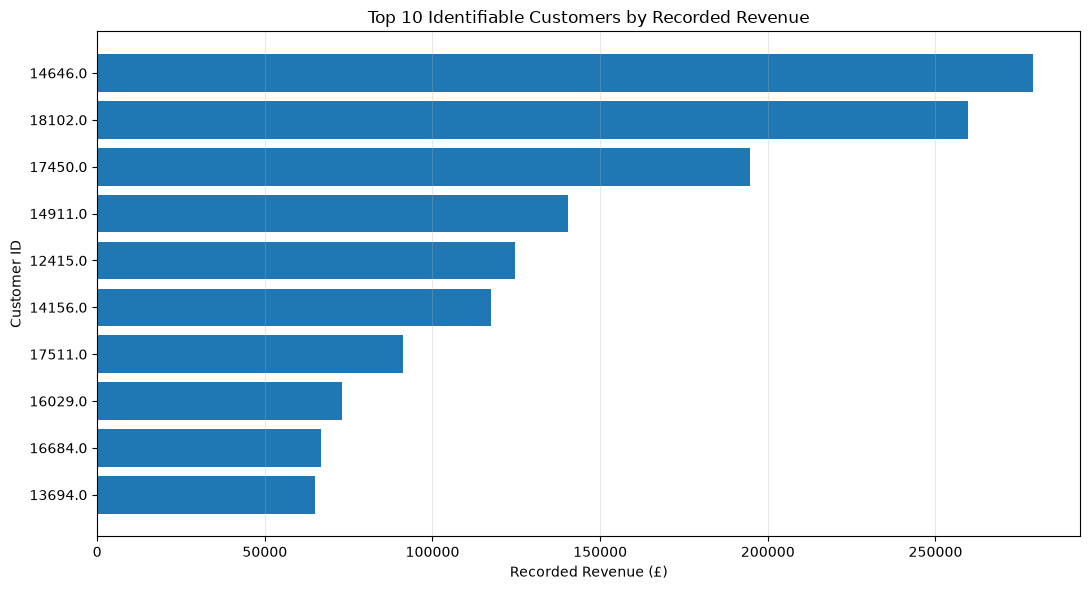

In [57]:
# STAGE 8: TOP 10 CUSTOMER REVENUE VISUALIZATION

top_customers = (
    customer_performance
    .head(10)
    .sort_values("RecordedRevenue", ascending=True)
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_customers["CustomerID"].astype(str),
    top_customers["RecordedRevenue"]
)

plt.title("Top 10 Identifiable Customers by Recorded Revenue")
plt.xlabel("Recorded Revenue (£)")
plt.ylabel("Customer ID")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

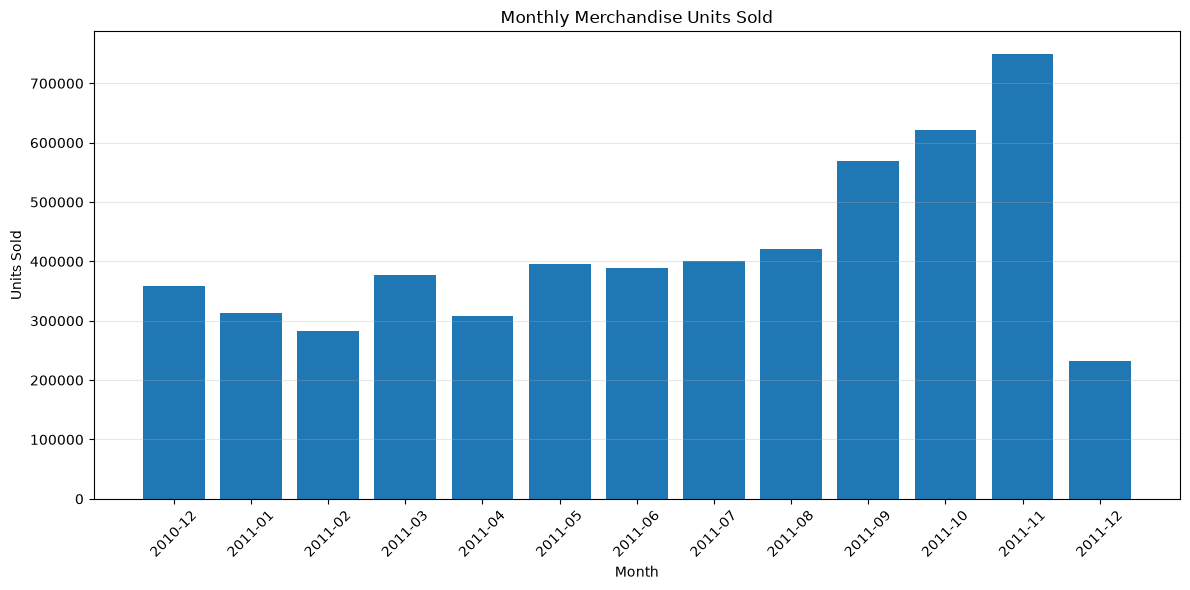

In [58]:
# STAGE 8: MONTHLY UNIT SALES VISUALIZATION

monthly_chart = monthly_performance.copy()
monthly_chart["Month"] = monthly_chart["Month"].astype(str)

plt.figure(figsize=(12, 6))

plt.bar(
    monthly_chart["Month"],
    monthly_chart["UnitsSold"]
)

plt.title("Monthly Merchandise Units Sold")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [59]:
# FINAL ANALYSIS: CONSOLIDATED BUSINESS FINDINGS

business_findings = pd.DataFrame({
    "Metric": [
        "Total merchandise revenue (sensitivity scenario)",
        "Products analysed",
        "Identifiable customers",
        "Countries represented",
        "Top 10 products revenue share",
        "Top 20 customers revenue share",
        "UK revenue share",
        "International revenue share",
        "Top 5 countries revenue share",
        "Average active months per customer",
        "Repeat-month customer share",
        "Highest revenue month"
    ],
    "Finding": [
        f"£{df_sensitivity['LineRevenue'].sum():,.2f}",
        f"{len(product_contribution):,}",
        f"{len(customer_performance):,}",
        f"{len(country_performance):,}",
        f"{product_contribution.head(10)['RevenueSharePct'].sum():.2f}%",
        f"{customer_performance.head(20)['RevenueSharePct'].sum():.2f}%",
        f"{uk_revenue_share:.2f}%",
        f"{international_revenue_share:.2f}%",
        f"{country_performance.head(5)['RevenueSharePct'].sum():.2f}%",
        f"{customer_months.mean():.2f} months",
        f"{(customer_months.gt(1).mean() * 100):.2f}%",
        str(monthly_performance.loc[
            monthly_performance['RecordedRevenue'].idxmax(), 'Month'
        ])
    ]
})

display(business_findings)

,Metric,Finding
0,Total merchandise revenue (sensitivity scenario),"£10,047,508.36"
1,Products analysed,"3,916"
2,Identifiable customers,"4,334"
3,Countries represented,38
4,Top 10 products revenue share,8.17%
5,Top 20 customers revenue share,22.78%
6,UK revenue share,84.78%
7,International revenue share,15.22%
8,Top 5 countries revenue share,94.24%
9,Average active months per customer,3.01 months


In [60]:
# STAGE 9: EXPORT CONSOLIDATED BUSINESS FINDINGS

import os

os.makedirs("../reports", exist_ok=True)

business_findings.to_csv(
    "../reports/business_findings.csv",
    index=False
)

print("Business findings exported successfully.")
print("../reports/business_findings.csv")

Business findings exported successfully.
../reports/business_findings.csv


In [61]:
# STAGE 9: CREATE FINAL REPORT FILE

from pathlib import Path

report_path = Path("../reports/final_business_analysis.md")

report_path.write_text(
    "# Retail Business Performance Analysis\n\n",
    encoding="utf-8"
)

print("Report file created successfully.")
print(report_path)

Report file created successfully.
..\reports\final_business_analysis.md


In [62]:
# STAGE 9: EXECUTIVE SUMMARY

executive_summary = """
## 1. Executive Summary

This project examines the historical transaction data of an online retailer
to understand its product performance, customer purchasing patterns,
monthly revenue trends, and geographical revenue distribution.

The analysis uses the UCI Online Retail dataset, containing transactions
recorded between December 2010 and December 2011.

After investigating data-quality issues and applying transparent
transaction filters, a merchandise dataset was prepared. A separate
sensitivity scenario excluded two independently verified fully cancelled
transactions.

Key findings include:

- The sensitivity-scenario recorded merchandise revenue was £10,047,508.36.
- The analysis covered 3,916 product stock codes.
- The top 10 products contributed 8.17% of recorded merchandise revenue.
- The top 20 identifiable customers contributed 22.78% of identifiable-customer revenue.
- The United Kingdom accounted for 84.78% of recorded merchandise revenue.
- International markets contributed 15.22%.
- Approximately 62.21% of identifiable customers purchased across multiple
  calendar months.
- November 2011 recorded the highest monthly merchandise revenue.

The findings indicate substantial geographical concentration in the
United Kingdom, alongside a broad distribution of revenue across products
and identifiable customers.

The analysis also identifies opportunities to investigate international
markets, product portfolio performance, and customer engagement.

Recorded revenue represents transaction value rather than profit.
The dataset does not contain the cost information required to assess
profitability.

All findings are limited to the historical dataset and the cleaning,
classification, and sensitivity assumptions documented in this report.
"""

with open("../reports/final_business_analysis.md", "a", encoding="utf-8") as file:
    file.write(executive_summary)

print("Executive Summary added successfully.")

Executive Summary added successfully.


In [63]:
# STAGE 9: BUSINESS PROBLEM AND OBJECTIVES

business_objectives = """
## 2. Business Problem and Objectives

### Business Problem

An online retailer generates transaction data across products,
customers, time periods, and geographical markets. However, raw
transaction records do not automatically reveal which areas contribute
most to recorded revenue or where management should investigate further.

This project uses historical transaction data to examine the retailer's
business performance and identify measurable patterns that can support
better-informed management decisions.

### Primary Business Question

Which products, customers, geographical markets, and sales periods
contribute most to the retailer's recorded revenue, and what
evidence-based actions could management consider?

### Analytical Objectives

1. Evaluate product-level recorded revenue and identify the highest-
   contributing products.
2. Examine monthly revenue, invoice activity, and changes in sales volume.
3. Investigate customer purchasing frequency and revenue concentration.
4. Compare recorded merchandise revenue across geographical markets.
5. Identify data-quality limitations that could affect interpretation.
6. Translate analytical findings into practical management
   recommendations.

### Analytical Framework

The project follows the PACE framework:

- **Plan:** Define the business question, objectives, and analytical scope.
- **Analyze:** Inspect, clean, classify, and investigate the transaction data.
- **Construct:** Develop analytical summaries, visualizations, and findings.
- **Execute:** Communicate results through a final report and
  evidence-based recommendations.
"""

with open("../reports/final_business_analysis.md", "a", encoding="utf-8") as file:
    file.write(business_objectives)

print("Business Problem and Objectives added successfully.")

Business Problem and Objectives added successfully.


In [64]:
# STAGE 9: DATASET OVERVIEW

dataset_overview = """
## 3. Dataset Overview

### Dataset Source

The analysis uses the Online Retail dataset published by the
UCI Machine Learning Repository.

- Dataset: Online Retail
- Source: UCI Machine Learning Repository
- DOI: https://doi.org/10.24432/C5BW33
- Original data provider: Daqing Chen
- Licence: CC BY 4.0
- Observation period: 1 December 2010 to 9 December 2011
- Original records: 541,909
- Original variables: 8

### Dataset Description

The dataset contains transaction-level records from a UK-based
online retailer.

| Variable | Description |
|---|---|
| InvoiceNo | Unique invoice identifier; cancellation invoices use a C prefix |
| StockCode | Product or transaction code |
| Description | Product or transaction description |
| Quantity | Number of units recorded in a transaction |
| InvoiceDate | Date and time of the transaction |
| UnitPrice | Unit price recorded in sterling |
| CustomerID | Customer identifier, where available |
| Country | Country associated with the transaction |

### Analytical Scope

The primary analysis focuses on merchandise transactions with:

- Positive quantities
- Positive unit prices
- Non-cancellation invoice numbers
- Stock codes other than identified special transaction codes

The resulting merchandise dataset contains 527,947 records
before the separate sensitivity adjustment.

The sensitivity scenario excludes two independently verified
fully cancelled original invoices, producing an adjusted
recorded merchandise revenue of £10,047,508.36.

The analysis retains the original raw dataset unchanged and
uses a separate processed dataset for merchandise analysis.
"""

with open("../reports/final_business_analysis.md", "a", encoding="utf-8") as file:
    file.write(dataset_overview)

print("Dataset Overview added successfully.")

Dataset Overview added successfully.


In [65]:
# STAGE 9: DATA CLEANING AND METHODOLOGY

cleaning_methodology = """
## 4. Data Cleaning and Methodology

### 4.1 Initial Data Inspection

The original dataset contained 541,909 transaction records and
8 variables.

Initial inspection identified:

- 135,080 records with missing CustomerID values.
- 1,454 records with missing product descriptions.
- 5,268 exact duplicate occurrences.
- 9,288 cancellation invoice records.
- Negative quantities and unusual unit-price values.
- Special transaction codes representing postage, discounts,
  manual entries, and adjustments.

### 4.2 Transaction Investigation

Several transaction categories were investigated before
constructing the merchandise dataset.

**Cancellations:** Invoice numbers beginning with C were
classified as cancellation records. All 9,288 such records
had negative quantities.

**Negative quantities without a cancellation prefix:** A
further 1,336 records had negative quantities without a C
invoice prefix. All had zero unit prices and missing
CustomerIDs. They were treated as operational or unusual
adjustment records rather than confirmed customer returns.

**Zero-price records:** A total of 2,515 records had zero
unit prices. These were excluded from the primary
revenue-generating merchandise analysis and retained for
separate data-quality consideration.

**Duplicate records:** The original dataset contained 5,268
exact duplicate occurrences. These were not automatically
removed because identical records may represent repeated
transaction lines. A deduplicated comparison showed a
recorded revenue difference of £21,740.98.

**Special transaction codes:** POST, DOT, M, D, B, and PADS
were investigated separately. These represent postage,
dotcom postage, manual entries, discounts, bad-debt
adjustments, and a special product or adjustment entry.
They were excluded from merchandise-level product analysis.

### 4.3 Merchandise Dataset Construction

The primary merchandise dataset retained records satisfying
the following conditions:

- Invoice number did not begin with C.
- Quantity was greater than zero.
- Unit price was greater than zero.
- Stock code was not one of the identified special
  transaction codes.

The resulting dataset contained 527,947 records,
representing 3,917 stock codes before product-level
aggregation.

A derived variable, LineRevenue, was calculated by
multiplying Quantity by UnitPrice.

LineRevenue represents recorded transaction value and
does not represent profit.

### 4.4 Cancellation Sensitivity Analysis

Two unusually large merchandise transactions were
independently matched to full-value cancellation invoices:

- Invoice 581483: £168,469.60.
- Invoice 541431: £77,183.60.

Their combined recorded value was £245,653.20.

Because broader automated cancellation matching produced
ambiguous and reusable matches, no additional original
transactions were automatically removed.

A separate sensitivity dataset excluded these two verified
original invoices. Its recorded merchandise revenue was
£10,047,508.36.

This is a sensitivity scenario, not a definitive
cancellation-adjusted net-sales figure.

### 4.5 Methodological Limitations

- Missing CustomerIDs limit customer-level analysis.
- Some product stock codes have multiple descriptions.
- Exact duplicate records may represent genuine repeated
  transaction lines.
- Cancellation matching could not reliably establish
  one-to-one relationships for all records.
- The dataset does not include product costs, operating
  expenses, or profit information.
- The historical observation period does not establish
  current business conditions.

These decisions were documented to preserve transparency
and avoid unsupported assumptions.
"""

with open("../reports/final_business_analysis.md", "a", encoding="utf-8") as file:
    file.write(cleaning_methodology)

print("Data Cleaning and Methodology added successfully.")

Data Cleaning and Methodology added successfully.


In [66]:
# STAGE 9: PRODUCT PERFORMANCE ANALYSIS

product_analysis = """
## 5. Product Performance Analysis

### 5.1 Product Revenue Overview

The sensitivity dataset was used to evaluate product-level
recorded merchandise revenue.

The analysis covered:

- 3,916 distinct product stock codes.
- 8.17% of recorded merchandise revenue from the top
  10 products.
- 12.02% from the top 20 products.
- 20.54% from the top 50 products.
- 31.37% from the top 100 products.

The results indicate that recorded merchandise revenue
was distributed across a broad product portfolio rather
than being dominated by a small number of products.

### 5.2 Highest-Contributing Products

The ten highest-contributing products by recorded
merchandise revenue in the sensitivity scenario were:

| Product | Recorded Revenue |
|---|---:|
| REGENCY CAKESTAND 3 TIER | £174,484.74 |
| WHITE HANGING HEART T-LIGHT HOLDER | £104,340.29 |
| PARTY BUNTING | £99,504.33 |
| JUMBO BAG RED RETROSPOT | £94,340.05 |
| RABBIT NIGHT LIGHT | £66,964.99 |
| PAPER CHAIN KIT 50'S CHRISTMAS | £64,952.29 |
| ASSORTED COLOUR BIRD ORNAMENT | £59,094.93 |
| CHILLI LIGHTS | £54,117.76 |
| PICNIC BASKET WICKER SMALL | £51,426.62 |
| POPCORN HOLDER | £51,354.02 |

### 5.3 Product Revenue Concentration

The cumulative revenue analysis identified the following
distribution:

| Revenue Threshold | Products Required | Share of Products |
|---|---:|---:|
| 50% | 248 | 6.33% |
| 80% | 843 | 21.53% |
| 90% | 1,352 | 34.53% |
| 95% | 1,821 | 46.50% |

Approximately 21.53% of product stock codes accounted
for 80% of recorded merchandise revenue.

This indicates some product-level revenue concentration,
although the distribution does not follow an exact
80/20 relationship.

### 5.4 Data Quality Considerations

The investigation identified unusual transactions that
could distort product rankings.

Two exceptionally large transactions were independently
verified as having corresponding full-value cancellations.
They were excluded from the sensitivity scenario.

Additionally, stock code 22502 was associated with more
than one product description. Product rankings were
therefore aggregated by stock code, while recognizing
that different descriptions may represent different
product entries.

### 5.5 Business Interpretation

Management could use these findings to:

- Monitor products contributing the largest recorded
  revenue.
- Review inventory requirements for important products.
- Investigate products with consistently low sales.
- Examine product descriptions and stock-code consistency.
- Avoid relying on revenue alone when evaluating
  product profitability.

The dataset does not provide product costs or margins,
so the analysis cannot determine which products are
the most profitable.
"""

with open("../reports/final_business_analysis.md", "a", encoding="utf-8") as file:
    file.write(product_analysis)

print("Product Performance Analysis added successfully.")

Product Performance Analysis added successfully.


In [67]:
# STAGE 9: MONTHLY SALES PERFORMANCE

monthly_analysis = """
## 6. Monthly Sales Performance

### 6.1 Monthly Revenue Trends

Monthly recorded merchandise revenue varied throughout
the observation period.

The highest monthly revenue occurred in November 2011,
at £1,458,925.53.

The lowest occurred in December 2011, at £447,247.00.
However, December 2011 is an incomplete month, with
transactions recorded only through December 9.

Other notable monthly results included:

| Month | Recorded Revenue | Unique Invoices |
|---|---:|---:|
| September 2011 | £1,031,430.36 | 1,821 |
| October 2011 | £1,107,449.54 | 2,008 |
| November 2011 | £1,458,925.53 | 2,753 |

### 6.2 Revenue and Invoice Activity

Between September and November 2011:

- Recorded merchandise revenue increased by 41.46%.
- Unique invoice count increased by 51.18%.
- Units sold increased by 31.61%.
- Recorded revenue per invoice decreased by 6.44%.

The increase in revenue coincided with a larger number
of invoices and more units sold. Average recorded revenue
per invoice declined over the same period.

These observations describe the pattern in the data and
do not establish the cause of the changes.

### 6.3 Monthly Data Coverage

The dataset does not cover every calendar day in the
observation period.

December 2010 and December 2011 are incomplete months.
January begins on January 4, April ends on April 28,
and October begins on October 2.

December 2011 ends on December 9, making direct
comparison with full calendar months inappropriate.

### 6.4 Business Interpretation

Management could investigate:

- The increase in invoice activity during September
  to November 2011.
- Product demand during the highest-revenue months.
- Whether changes in invoice volume corresponded with
  changes in units purchased.
- Seasonal patterns across comparable complete periods.

The historical dataset alone cannot establish whether
these patterns would recur in future periods.
"""

with open("../reports/final_business_analysis.md", "a", encoding="utf-8") as file:
    file.write(monthly_analysis)

print("Monthly Sales Performance added successfully.")

Monthly Sales Performance added successfully.


In [68]:
# STAGE 9: CUSTOMER ANALYSIS

customer_analysis = """
## 7. Customer Analysis

### 7.1 Customer Overview

The analysis identified 4,334 customers with available
CustomerIDs in the sensitivity dataset.

Customer-level analysis was restricted to records with
non-missing CustomerIDs. Consequently, the results do not
represent the entire customer population.

### 7.2 Customer Purchasing Frequency

Customer activity was measured by the number of distinct
calendar months in which each identifiable customer
recorded a purchase.

Key findings:

- 1,638 customers (37.79%) were active in one month.
- 2,696 customers (62.21%) were active across multiple
  months.
- The average customer was active in 3.01 months.
- 84 customers (1.94%) were active in 12 or 13 months.

This measures observed multi-month purchasing activity,
not a formal customer retention rate.

### 7.3 Customer Revenue Concentration

The top 10 identifiable customers contributed 16.56%
of identifiable-customer recorded merchandise revenue.

The top 20 contributed 22.78%.

The cumulative concentration analysis found:

| Revenue Threshold | Customers Required | Share of Customers |
|---|---:|---:|
| 50% | 232 | 5.35% |
| 80% | 1,166 | 26.90% |
| 90% | 1,941 | 44.79% |
| 95% | 2,628 | 60.64% |

This suggests that revenue was distributed across a
relatively broad identifiable customer base, although
a smaller group contributed a substantial share.

### 7.4 Data Limitations

Approximately 24.9% of merchandise records had missing
CustomerIDs.

Customers whose identifiers were missing could not
be reliably included in customer-level grouping.

The analysis therefore describes identifiable-customer
purchasing patterns rather than the complete customer
population.

### 7.5 Business Interpretation

Management could consider:

- Studying purchasing patterns among repeat-month customers.
- Investigating the characteristics of high-revenue customers.
- Developing customer segmentation using purchasing
  frequency and recorded revenue.
- Evaluating retention initiatives using more complete
  customer identification data.

These recommendations require further investigation.
The observed data does not establish the effectiveness
of any particular retention strategy.
"""

with open("../reports/final_business_analysis.md", "a", encoding="utf-8") as file:
    file.write(customer_analysis)

print("Customer Analysis added successfully.")

Customer Analysis added successfully.


In [69]:
# STAGE 9: GEOGRAPHICAL PERFORMANCE ANALYSIS

geographical_analysis = """
## 8. Geographical Performance Analysis

### 8.1 Revenue Distribution by Country

The retailer's recorded merchandise revenue was heavily
concentrated in the United Kingdom.

The country-level analysis covered 38 countries.

| Country | Recorded Revenue | Revenue Share |
|---|---:|---:|
| United Kingdom | £8,518,060.96 | 84.78% |
| Netherlands | £283,889.34 | 2.83% |
| EIRE | £276,404.30 | 2.75% |
| Germany | £205,569.89 | 2.05% |
| France | £184,768.74 | 1.84% |

### 8.2 Domestic and International Contribution

- United Kingdom revenue share: 84.78%.
- International revenue share: 15.22%.
- Top five countries combined revenue share: 94.24%.

The results indicate substantial dependence on the
United Kingdom market.

International revenue was distributed across a number
of smaller markets, with the Netherlands, EIRE, Germany,
and France among the largest contributors after the UK.

### 8.3 Business Interpretation

Management could consider:

- Investigating the commercial potential of established
  international markets.
- Comparing order volumes and customer activity across
  countries.
- Evaluating shipping, fulfilment, and operating costs
  before considering expansion.
- Monitoring geographical revenue concentration as
  part of business risk analysis.

The dataset does not contain market-size, shipping-cost,
marketing-cost, or country-level profitability data.
Therefore, revenue contribution alone cannot establish
the attractiveness of international expansion.
"""

with open("../reports/final_business_analysis.md", "a", encoding="utf-8") as file:
    file.write(geographical_analysis)

print("Geographical Performance Analysis added successfully.")

Geographical Performance Analysis added successfully.


In [70]:
# STAGE 9: BUSINESS INSIGHTS AND RECOMMENDATIONS

recommendations = """
## 9. Key Business Insights and Recommendations

### Insight 1: Strong Geographical Revenue Concentration

The United Kingdom contributed 84.78% of recorded
merchandise revenue, while international markets
contributed 15.22%.

**Recommendation:**
Management could investigate opportunities in
established international markets, particularly the
Netherlands, EIRE, Germany, and France. Before
committing resources, it should evaluate shipping
costs, market demand, and country-level profitability.

### Insight 2: Broad Product Revenue Distribution

The top 10 products contributed 8.17% of recorded
merchandise revenue. Approximately 21.53% of stock
codes accounted for 80% of revenue.

**Recommendation:**
Management could monitor high-contributing products
while reviewing inventory requirements and sales
performance across the wider product portfolio.
Product-level cost and margin data would be needed
to identify the most profitable products.

### Insight 3: Customer Revenue Is Distributed Across
a Broad Identifiable Customer Base

The top 20 identifiable customers contributed
22.78% of identifiable-customer recorded revenue.

**Recommendation:**
Management could develop customer segments based
on purchasing frequency and recorded revenue.
Further investigation could identify opportunities
for customer engagement and retention initiatives.

### Insight 4: Repeat-Month Purchasing Activity

Approximately 62.21% of identifiable customers
recorded purchases across multiple calendar months.

**Recommendation:**
Management could examine repeat purchasing patterns
and compare the purchasing behaviour of one-month
and multi-month customers. More complete customer
identification would improve the reliability of
this analysis.

### Insight 5: Increased Activity Toward November 2011

From September to November 2011, recorded revenue
increased by 41.46%, while invoice count increased
by 51.18%.

**Recommendation:**
Management could investigate the products, customer
segments, and transaction patterns associated with
this increase. Comparable historical periods could
help assess whether similar patterns recur.

### Overall Management Perspective

The analysis highlights geographical concentration,
product portfolio distribution, customer purchasing
patterns, and changes in monthly sales activity.

These findings can guide further investigation and
support more informed decisions. They should not
be treated as proof of profitability, causation,
or future performance.
"""

with open("../reports/final_business_analysis.md", "a", encoding="utf-8") as file:
    file.write(recommendations)

print("Business Insights and Recommendations added successfully.")

Business Insights and Recommendations added successfully.


In [71]:
# STAGE 9: LIMITATIONS AND CONCLUSION

limitations_conclusion = """
## 10. Limitations

The findings of this project should be interpreted
within the following limitations:

1. **Historical data:** The dataset covers December 2010
   to December 2011 and does not represent current
   retail conditions.

2. **Missing customer identifiers:** Approximately
   24.9% of merchandise records have missing CustomerIDs,
   limiting customer-level analysis.

3. **Cancellation reconciliation:** Two fully cancelled
   original transactions were independently verified
   and excluded in the sensitivity scenario. Broader
   cancellation matching remained ambiguous, so the
   resulting revenue is not definitive net sales.

4. **Duplicate records:** Exact duplicate occurrences
   were investigated but not automatically removed
   because identical rows may represent repeated
   transaction lines.

5. **Profitability:** Product costs, operating expenses,
   shipping costs, and profit margins are unavailable.
   Recorded revenue cannot establish profitability.

6. **Incomplete periods:** December 2010 and December
   2011 are incomplete, limiting direct monthly
   comparisons.

7. **Descriptive analysis:** The project identifies
   patterns and associations in historical transactions.
   It does not establish causation or predict future
   business performance.

## 11. Conclusion

This project examined historical online retail
transactions to understand product performance,
monthly sales activity, customer purchasing patterns,
and geographical revenue distribution.

The analysis identified a substantial concentration
of recorded merchandise revenue in the United Kingdom,
alongside a broad distribution of revenue across
products and identifiable customers.

It also highlighted repeat-month purchasing activity
among identifiable customers and an increase in
invoice activity and recorded revenue toward
November 2011.

The data-quality investigation was an important part
of the project. It helped identify unusual transactions,
special transaction codes, duplicate records, and
cancellation-related limitations that could affect
analytical conclusions.

Overall, the project demonstrates a structured
approach to transforming raw transaction records
into documented business insights and practical
management recommendations.

Further analysis using current transaction data,
complete customer identifiers, and product cost
information could provide a stronger basis for
operational and strategic decisions.
"""

with open("../reports/final_business_analysis.md", "a", encoding="utf-8") as file:
    file.write(limitations_conclusion)

print("Limitations and Conclusion added successfully.")

Limitations and Conclusion added successfully.


In [72]:
# STAGE 9: FINAL REPORT STRUCTURE CHECK

from pathlib import Path

report_path = Path("../reports/final_business_analysis.md")

report_text = report_path.read_text(encoding="utf-8")

headings = [
    line for line in report_text.splitlines()
    if line.startswith("## ")
]

print("REPORT QUALITY CHECK")
print("--------------------")
print("Report exists:", report_path.exists())
print("Total words:", len(report_text.split()))
print("Total sections:", len(headings))
print("\nSECTION HEADINGS:")

for heading in headings:
    print(heading)

print("\nReport file size:", report_path.stat().st_size, "bytes")

REPORT QUALITY CHECK
--------------------
Report exists: True
Total words: 2913
Total sections: 11

SECTION HEADINGS:
## 1. Executive Summary
## 2. Business Problem and Objectives
## 3. Dataset Overview
## 4. Data Cleaning and Methodology
## 5. Product Performance Analysis
## 6. Monthly Sales Performance
## 7. Customer Analysis
## 8. Geographical Performance Analysis
## 9. Key Business Insights and Recommendations
## 10. Limitations
## 11. Conclusion

Report file size: 22593 bytes


In [73]:
# STAGE 9: VISUALIZATION FILE CHECK

from pathlib import Path

visualization_folder = Path("../visualizations")
visualization_folder.mkdir(parents=True, exist_ok=True)

chart_files = list(visualization_folder.glob("*"))

print("VISUALIZATION FOLDER CHECK")
print("--------------------------")
print("Folder exists:", visualization_folder.exists())
print("Saved files:", len(chart_files))

for file in chart_files:
    print(file.name)

VISUALIZATION FOLDER CHECK
--------------------------
Folder exists: True
Saved files: 1
.gitkeep


In [74]:
# CHECK DATAFRAMES REQUIRED TO SAVE CHARTS

required_objects = [
    "country_performance",
    "monthly_performance",
    "product_contribution",
    "customer_performance",
    "customer_months",
    "monthly_customers",
    "df_sensitivity"
]

for name in required_objects:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")

country_performance: Available
monthly_performance: Available
product_contribution: Available
customer_performance: Available
customer_months: Available
monthly_customers: Available
df_sensitivity: Available


In [75]:
# SAVE PROJECT VISUALIZATIONS

import matplotlib.pyplot as plt
from pathlib import Path

visualization_folder = Path("../visualizations")
visualization_folder.mkdir(parents=True, exist_ok=True)

# 1. Top 10 countries by revenue
plot_data = country_performance.nlargest(10, "RecordedRevenue").sort_values("RecordedRevenue")

plt.figure(figsize=(10, 6))
plt.barh(plot_data["Country"], plot_data["RecordedRevenue"])
plt.title("Top 10 Countries by Recorded Merchandise Revenue")
plt.xlabel("Recorded Revenue (£)")
plt.tight_layout()
plt.savefig(visualization_folder / "01_top_countries.png", dpi=300)
plt.close()

# 2. Monthly revenue trend
plot_data = monthly_performance.copy()

plt.figure(figsize=(12, 6))
plt.plot(plot_data["Month"].astype(str), plot_data["RecordedRevenue"], marker="o")
plt.title("Monthly Recorded Merchandise Revenue")
plt.xlabel("Month")
plt.ylabel("Recorded Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(visualization_folder / "02_monthly_revenue.png", dpi=300)
plt.close()

# 3. Top 10 products by revenue
plot_data = product_contribution.nlargest(10, "RecordedRevenue").sort_values("RecordedRevenue")

plt.figure(figsize=(11, 7))
plt.barh(plot_data["Description"], plot_data["RecordedRevenue"])
plt.title("Top 10 Products by Recorded Merchandise Revenue")
plt.xlabel("Recorded Revenue (£)")
plt.tight_layout()
plt.savefig(visualization_folder / "03_top_products.png", dpi=300)
plt.close()

# 4. Cumulative customer revenue contribution
plot_data = customer_performance.sort_values("RecordedRevenue", ascending=False).copy()
plot_data["CumulativeShare"] = (
    plot_data["RecordedRevenue"].cumsum()
    / plot_data["RecordedRevenue"].sum() * 100
)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(plot_data) + 1), plot_data["CumulativeShare"])
plt.title("Cumulative Identifiable Customer Revenue Contribution")
plt.xlabel("Customer Rank")
plt.ylabel("Cumulative Revenue Share (%)")
plt.tight_layout()
plt.savefig(visualization_folder / "04_customer_revenue_concentration.png", dpi=300)
plt.close()

# 5. Cumulative product revenue contribution
plot_data = product_contribution.sort_values("RecordedRevenue", ascending=False).copy()
plot_data["CumulativeShare"] = (
    plot_data["RecordedRevenue"].cumsum()
    / plot_data["RecordedRevenue"].sum() * 100
)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(plot_data) + 1), plot_data["CumulativeShare"])
plt.title("Cumulative Product Revenue Contribution")
plt.xlabel("Product Rank")
plt.ylabel("Cumulative Revenue Share (%)")
plt.tight_layout()
plt.savefig(visualization_folder / "05_product_revenue_concentration.png", dpi=300)
plt.close()

# 6. Monthly invoice activity
plot_data = monthly_performance.copy()

plt.figure(figsize=(12, 6))
plt.bar(plot_data["Month"].astype(str), plot_data["InvoiceCount"])
plt.title("Monthly Invoice Activity")
plt.xlabel("Month")
plt.ylabel("Unique Invoices")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(visualization_folder / "06_monthly_invoice_activity.png", dpi=300)
plt.close()

# 7. Customer distribution by active months
active_month_distribution = customer_months.value_counts().sort_index()

plt.figure(figsize=(10, 6))
plt.bar(active_month_distribution.index.astype(str), active_month_distribution.values)
plt.title("Customer Distribution by Active Months")
plt.xlabel("Number of Active Months")
plt.ylabel("Number of Identifiable Customers")
plt.tight_layout()
plt.savefig(visualization_folder / "07_customer_active_months.png", dpi=300)
plt.close()

# 8. Top 10 identifiable customers
plot_data = customer_performance.nlargest(10, "RecordedRevenue").copy()
plot_data["CustomerLabel"] = plot_data["CustomerID"].astype(int).astype(str)
plot_data = plot_data.sort_values("RecordedRevenue")

plt.figure(figsize=(10, 6))
plt.barh(plot_data["CustomerLabel"], plot_data["RecordedRevenue"])
plt.title("Top 10 Identifiable Customers by Recorded Revenue")
plt.xlabel("Recorded Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.savefig(visualization_folder / "08_top_customers.png", dpi=300)
plt.close()

# 9. Monthly units sold
plot_data = monthly_performance.copy()

plt.figure(figsize=(12, 6))
plt.plot(plot_data["Month"].astype(str), plot_data["UnitsSold"], marker="o")
plt.title("Monthly Merchandise Units Sold")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(visualization_folder / "09_monthly_units_sold.png", dpi=300)
plt.close()

print("All nine visualizations saved successfully.")

All nine visualizations saved successfully.


In [76]:
# VERIFY SAVED VISUALIZATIONS

from pathlib import Path

visualization_folder = Path("../visualizations")
chart_files = sorted(visualization_folder.glob("*.png"))

print("SAVED CHARTS")
print("------------")

for chart in chart_files:
    print(f"{chart.name} — {chart.stat().st_size:,} bytes")

print("\nTotal PNG files:", len(chart_files))
print("All nine charts saved:", len(chart_files) == 9)

SAVED CHARTS
------------
01_top_countries.png — 101,755 bytes
02_monthly_revenue.png — 202,974 bytes
03_top_products.png — 149,845 bytes
04_customer_revenue_concentration.png — 115,854 bytes
05_product_revenue_concentration.png — 119,181 bytes
06_monthly_invoice_activity.png — 111,904 bytes
07_customer_active_months.png — 92,533 bytes
08_top_customers.png — 96,866 bytes
09_monthly_units_sold.png — 182,099 bytes

Total PNG files: 9
All nine charts saved: True


In [77]:
# INSPECT EXISTING README

from pathlib import Path

readme_path = Path("../README.md")

if readme_path.exists():
    print(readme_path.read_text(encoding="utf-8"))
else:
    print("README.md does not exist yet.")

# Retail Business Performance Analysis

**An independent Foundations of Data Science project using the PACE framework**

## Business question

Which products, customers, and sales periods contribute most to revenue in a historical online retail business, and what evidence-based actions could management consider to improve sales performance?

## Project overview

This project uses the UCI Online Retail dataset, a real transaction-level dataset from a UK-based online retailer. The original data covers transactions from **1 December 2010 to 9 December 2011** and contains **541,909 records**.

The project follows the PACE framework:

1. **Plan** — define the business problem, stakeholders, objectives, and analytical questions.
2. **Analyze** — inspect the dataset, assess data quality, and identify patterns worth investigating.
3. **Construct** — prepare analysis-ready data, calculate business metrics, and create visual evidence.
4. **Execute** — communicate findings, limitations, and pract

In [78]:
# INSPECT README STRUCTURE

from pathlib import Path

readme_path = Path("../README.md")
readme_text = readme_path.read_text(encoding="utf-8")

print("README HEADINGS")
print("---------------")

for line in readme_text.splitlines():
    if line.startswith("#"):
        print(line)

print("\nREADME ENDING")
print("-------------")
print("\n".join(readme_text.splitlines()[-35:]))

print("\nTotal words:", len(readme_text.split()))

README HEADINGS
---------------
# Retail Business Performance Analysis
## Business question
## Project overview
## Initial analytical questions
## Dataset
## Important measurement note
## Repository structure
## Reproducibility
## Current status
## Attribution

README ENDING
-------------
│   ├── raw/                 # Original dataset; do not commit large raw files
│   └── processed/           # Cleaned/derived data (review before committing)
├── notebooks/
│   └── 01_initial_data_understanding.ipynb
├── reports/                 # Written findings and project report
├── visualizations/          # Exported charts
├── .gitignore
├── PROJECT_PLAN.md
├── DATA_DICTIONARY.md
└── requirements.txt
```

## Reproducibility

Use Python 3.10+ and install the dependencies:

```bash
pip install -r requirements.txt
```

Open the notebook and run the cells in order.

## Current status

- [x] Business problem selected
- [x] Dataset source selected
- [x] Initial project structure created
- [ ] Download

In [79]:
# UPDATE README WITH COMPLETED PROJECT FINDINGS

from pathlib import Path

readme_path = Path("../README.md")
readme_text = readme_path.read_text(encoding="utf-8")

new_sections = """
## Key findings

The analysis produced the following findings using the
sensitivity-analysis dataset:

- **Recorded merchandise revenue:** £10,047,508.36.
- **Products analysed:** 3,916 stock codes.
- **Identifiable customers:** 4,334.
- **Countries represented:** 38.
- **United Kingdom revenue contribution:** 84.78%.
- **International revenue contribution:** 15.22%.
- **Top 10 products:** 8.17% of recorded merchandise revenue.
- **Top 20 identifiable customers:** 22.78% of identifiable-customer revenue.
- **Multi-month purchasing activity:** 62.21% of identifiable customers.
- **Highest recorded revenue month:** November 2011.

These results describe historical recorded transaction
values. They should not be interpreted as profit or
verified net sales.

## Visualizations

The project includes nine exported visualizations:

### Geographical performance

![Top 10 countries](visualizations/01_top_countries.png)

### Monthly sales performance

![Monthly revenue](visualizations/02_monthly_revenue.png)

![Monthly invoice activity](visualizations/06_monthly_invoice_activity.png)

![Monthly units sold](visualizations/09_monthly_units_sold.png)

### Product performance

![Top products](visualizations/03_top_products.png)

![Product revenue concentration](visualizations/05_product_revenue_concentration.png)

### Customer analysis

![Customer revenue concentration](visualizations/04_customer_revenue_concentration.png)

![Customer active months](visualizations/07_customer_active_months.png)

![Top identifiable customers](visualizations/08_top_customers.png)

## Final report and project outputs

The repository contains:

- `reports/final_business_analysis.md` — complete business analysis report.
- `reports/business_findings.csv` — consolidated analytical findings.
- `data/processed/merchandise_cleaned.csv` — prepared merchandise dataset.
- `visualizations/` — exported analytical charts.
- `notebooks/01_initial_data_understanding.ipynb` — exploratory analysis and data preparation.

## Analytical limitations

The findings have several important limitations:

- The dataset represents historical transactions from 2010–2011.
- Approximately 24.9% of merchandise records have missing CustomerIDs.
- Two fully cancelled transactions were independently verified and excluded in a sensitivity scenario. Broader cancellation matching remained ambiguous.
- Exact duplicate records were retained in the primary analysis because identical rows do not necessarily establish accidental duplication.
- Product costs, operating expenses, and profit margins are unavailable.
- December 2011 is an incomplete observation period.

Accordingly, recorded merchandise revenue is not equivalent
to profit or definitive net sales. Customer and product
findings should be interpreted within the documented
data-quality limitations.

"""

if "## Key findings" not in readme_text:
    readme_text = readme_text.replace(
        "## Attribution",
        new_sections + "## Attribution",
        1
    )
    readme_path.write_text(readme_text, encoding="utf-8")
    print("README updated successfully.")
else:
    print("Key findings section already exists. No changes made.")

README updated successfully.


In [80]:
# FINAL README AND REPOSITORY CHECK

from pathlib import Path

project_root = Path("..")

readme_path = project_root / "README.md"
report_path = project_root / "reports" / "final_business_analysis.md"

required_files = [
    "notebooks/01_initial_data_understanding.ipynb",
    "reports/final_business_analysis.md",
    "reports/business_findings.csv",
    "data/processed/merchandise_cleaned.csv",
    "requirements.txt",
    "PROJECT_PLAN.md",
    "DATA_DICTIONARY.md"
]

print("PROJECT FILE CHECK")
print("------------------")

for file in required_files:
    exists = (project_root / file).exists()
    print(f"{'FOUND' if exists else 'MISSING'}: {file}")

print("\nREADME SECTION CHECK")
print("--------------------")

readme_text = readme_path.read_text(encoding="utf-8")

for heading in [
    "## Key findings",
    "## Visualizations",
    "## Final report and project outputs",
    "## Analytical limitations",
    "## Attribution"
]:
    print(f"{'FOUND' if heading in readme_text else 'MISSING'}: {heading}")

print("\nChart references:", readme_text.count("visualizations/"))
print("Report exists:", report_path.exists())

PROJECT FILE CHECK
------------------
FOUND: notebooks/01_initial_data_understanding.ipynb
FOUND: reports/final_business_analysis.md
FOUND: reports/business_findings.csv
FOUND: data/processed/merchandise_cleaned.csv
FOUND: requirements.txt
FOUND: PROJECT_PLAN.md
FOUND: DATA_DICTIONARY.md

README SECTION CHECK
--------------------
FOUND: ## Key findings
FOUND: ## Visualizations
FOUND: ## Final report and project outputs
FOUND: ## Analytical limitations
FOUND: ## Attribution

Chart references: 11
Report exists: True


In [81]:
# GITHUB PUBLICATION READINESS CHECK

from pathlib import Path

project_root = Path("..")

# Check .gitignore
gitignore_path = project_root / ".gitignore"

print("GITIGNORE")
print("---------")

if gitignore_path.exists():
    print(gitignore_path.read_text(encoding="utf-8"))
else:
    print(".gitignore is missing.")

# Check requirements
requirements_path = project_root / "requirements.txt"

print("\nREQUIREMENTS")
print("------------")

if requirements_path.exists():
    print(requirements_path.read_text(encoding="utf-8"))
else:
    print("requirements.txt is missing.")

# Check raw dataset
raw_file = project_root / "data" / "raw" / "Online Retail.xlsx"

print("\nRAW DATASET")
print("-----------")
print("Original Excel dataset exists:", raw_file.exists())

GITIGNORE
---------
# Python
__pycache__/
*.py[cod]
.venv/
venv/
.env

# Jupyter
.ipynb_checkpoints/

# Raw and generated data
data/raw/*
!data/raw/.gitkeep
data/processed/*
!data/processed/.gitkeep

# Local editor/system files
.vscode/
.DS_Store
Thumbs.db


REQUIREMENTS
------------
pandas
numpy
matplotlib
seaborn
openpyxl
jupyter
notebook


RAW DATASET
-----------
Original Excel dataset exists: True


In [82]:
# CHECK DEPENDENCIES AND DATA FILE SIZES

from pathlib import Path

project_root = Path("..")

print("REQUIREMENTS")
print("------------")
print(
    (project_root / "requirements.txt").read_text(
        encoding="utf-8"
    )
)

print("\nDATA FILE SIZES")
print("---------------")

for file in [
    project_root / "data/raw/Online Retail.xlsx",
    project_root / "data/processed/merchandise_cleaned.csv"
]:
    if file.exists():
        print(f"{file.name}: {file.stat().st_size / (1024**2):.2f} MB")
    

REQUIREMENTS
------------
pandas
numpy
matplotlib
seaborn
openpyxl
jupyter
notebook


DATA FILE SIZES
---------------
Online Retail.xlsx: 22.62 MB
merchandise_cleaned.csv: 48.84 MB


In [83]:
# CLARIFY DATASET AVAILABILITY IN README

from pathlib import Path

readme_path = Path("../README.md")
readme_text = readme_path.read_text(encoding="utf-8")

old_text = (
    "- `data/processed/merchandise_cleaned.csv` — "
    "prepared merchandise dataset."
)

new_text = (
    "- `data/processed/merchandise_cleaned.csv` — "
    "prepared merchandise dataset generated locally "
    "by the notebook; excluded from GitHub because "
    "of its file size."
)

if old_text in readme_text:
    readme_text = readme_text.replace(old_text, new_text)
    readme_path.write_text(readme_text, encoding="utf-8")
    print("README data-file documentation updated.")
else:
    print("Exact bullet not found. No changes made.")

README data-file documentation updated.


In [84]:
# FINAL GIT PUBLICATION CHECK

import subprocess
from pathlib import Path

project_root = Path("..").resolve()

def git_command(*args):
    return subprocess.run(
        ["git", *args],
        cwd=project_root,
        capture_output=True,
        text=True
    )

# Check Git repository
result = git_command("rev-parse", "--is-inside-work-tree")
print("Git repository initialized:", result.returncode == 0)

if result.returncode == 0:

    print("\nGIT STATUS")
    print("----------")

    status = git_command("status", "--short")
    print(status.stdout if status.stdout else "No uncommitted changes.")

    print("\nIGNORED FILE CHECK")
    print("------------------")

    for file in [
        "data/raw/Online Retail.xlsx",
        "data/processed/merchandise_cleaned.csv",
        ".venv"
    ]:
        check = git_command("check-ignore", file)
        print(f"{file}: {'Ignored' if check.returncode == 0 else 'Not ignored'}")

else:
    print(result.stderr)

Git repository initialized: False
fatal: not a git repository (or any of the parent directories): .git



## Record your observations

After running the notebook, document:
1. Dataset dimensions and date coverage.
2. Missing-value and duplicate counts.
3. Counts of cancellation rows, negative quantities, and non-positive prices.
4. Questions that need investigation before cleaning.

**Do not drop rows simply because values are negative or missing.** First determine what those records represent and how their treatment changes the business metrics.